# CosmoTokens: CNN vs GOTHAM-inspired Transformer decoder

**Updated mount fix:** this notebook first checks whether Google Drive is already available. If not, it chooses an empty mountpoint instead of calling `drive.mount()` on a non-empty `/content/drive` directory.

It reuses the existing `MyDrive/CosmoTokens` data and simulation split, then compares the CNN baseline with a GOTHAM-inspired CNN + Transformer decoder. This is an adaptation, not an exact reproduction of GOTHAM.

**Runtime estimate:** around 1–3 hours on a Colab T4 GPU, potentially longer depending on runtime and validation speed.

**Scientific caution:** the project's existing test set has been examined during earlier iterations, so test results are exploratory.

Mounted at /content/drive
COSMOTOKENS — CNN vs GOTHAM-INSPIRED TRANSFORMER DECODER
Device: cuda
GPU: Tesla T4
Output: /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1
Seeds: [101, 202, 303]
Epoch cap: 60
Train simulations × views/epoch: 800 × 4
Loaded maps: (15000, 64, 64)
Train/validation/test simulations: 800 100 100
Target mean: [0.29881 0.79787 1.37286 1.33537 1.08712 1.09251]
Target std: [0.11643 0.11651 1.04214 1.01402 0.42652 0.43204]
Note: test set has been used in previous project iterations; treat its results as exploratory.

CNN seed=101: 610,630 trainable parameters
CNN seed=101 epoch=01 train_MSE=0.9294 val_score=0.7667
CNN seed=101 epoch=02 train_MSE=0.8644 val_score=0.7141
CNN seed=101 epoch=03 train_MSE=0.8368 val_score=0.7061
CNN seed=101 epoch=04 train_MSE=0.8234 val_score=0.6973
CNN seed=101 epoch=05 train_MSE=0.8110 val_score=0.6889
CNN seed=101 epoch=06 train_MSE=0.8059 val_score=0.6990
CNN seed=101 epoch=07 train_MSE=0.8117 val_score=0.6831
CNN see

,model,seed,best_epoch,best_robust_val_normalized_MAE
0,CNN,101,24,0.629792
1,CNN,202,27,0.628598
2,CNN,303,55,0.624725
3,GOTHAM_INSPIRED_DECODER,101,57,0.607165
4,GOTHAM_INSPIRED_DECODER,202,49,0.618925
5,GOTHAM_INSPIRED_DECODER,303,48,0.610760


Evaluated CNN seed=101
Evaluated CNN seed=202
Evaluated CNN seed=303
Evaluated GOTHAM_INSPIRED_DECODER seed=101
Evaluated GOTHAM_INSPIRED_DECODER seed=202
Evaluated GOTHAM_INSPIRED_DECODER seed=303


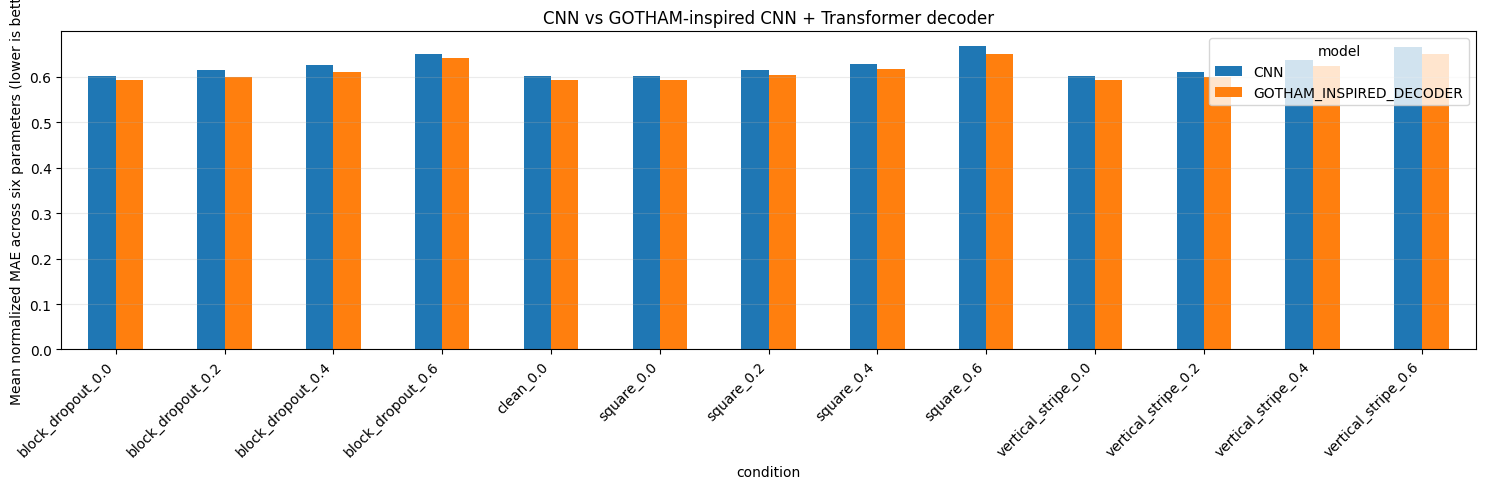


EXPERIMENT COMPLETE
Outputs:
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/training_summary.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/test_metrics_per_seed.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/test_metrics_seed_ensemble.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/paired_bootstrap_CI.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/overall_condition_summary.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/cnn_vs_gotham_inspired_transformer.png
 - /content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/run_manifest.json
Total elapsed: 0.28 hours

Interpretation guide:
 - Lower normalized_MAE is better.
 - In paired_bootstrap_CI.csv, negative delta favours the Transformer-inspired model.
 - If the 95% CI crosses zero, evidence for a performance difference is inconclusive.
 - Because this test set was previously examined,

In [ ]:

# =============================================================================
# COSMOTOKENS: CNN vs GOTHAM-INSPIRED CNN + TRANSFORMER DECODER
# Google Colab, end-to-end training/evaluation
#
# Important scientific distinction:
# This adapts GOTHAM's architectural idea (CNN/residual encoder + Transformer
# decoder with cross-attention) to 2D CAMELS stellar-mass maps and six scalar
# regression targets. It is NOT a literal reproduction of GOTHAM: GOTHAM uses
# three 3D PM density fields and autoregressively generates tokenized halo
# catalogues. Six simultaneous scalar parameters do not require halo-token
# autoregressive decoding.
#
# Uses existing data and the existing simulation-level split. Trains both the
# CNN baseline and the adapted model under the same protocol for a fairer
# comparison. Test metrics are exploratory because the test set has been
# examined in previous CosmoTokens iterations.
# =============================================================================

import os, gc, json, time, random, math, warnings
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------- ROBUST GOOGLE DRIVE MOUNT ---------------------------
# Colab raises "Mountpoint must not already contain files" when drive.mount()
# is called on a non-empty directory that is not the intended mountpoint.
# First reuse an existing mount; otherwise choose an empty mountpoint.
from google.colab import drive

mount_candidates = [Path("/content/drive"), Path("/content/gdrive")]
mount_candidates += [Path(f"/content/gdrive{i}") for i in range(2, 10)]
MOUNTPOINT = None

for candidate in mount_candidates:
    # If Drive is already mounted here, reuse it without calling mount again.
    if (candidate / "MyDrive").exists():
        MOUNTPOINT = candidate
        print(f"Google Drive already available at: {MOUNTPOINT}")
        break

if MOUNTPOINT is None:
    for candidate in mount_candidates:
        if candidate.is_symlink():
            continue
        if not candidate.exists():
            candidate.mkdir(parents=True, exist_ok=True)
        # Only attempt to mount into an empty directory.
        if candidate.is_dir() and not any(candidate.iterdir()):
            MOUNTPOINT = candidate
            break

if MOUNTPOINT is None:
    raise RuntimeError(
        "Could not find an empty Google Drive mountpoint. "
        "In Colab, inspect /content and remove/rename only the accidental "
        "empty mount directory, or restart the runtime and rerun this cell."
    )

if not (MOUNTPOINT / "MyDrive").exists():
    drive.mount(str(MOUNTPOINT), force_remount=False)
    if not (MOUNTPOINT / "MyDrive").exists():
        raise RuntimeError(
            f"Drive mount did not expose MyDrive at {MOUNTPOINT}. "
            "Complete the Colab Drive authorization and rerun."
        )

# ------------------------------ CONFIG ---------------------------------------
ROOT = MOUNTPOINT / "MyDrive" / "CosmoTokens"
OUT = ROOT / "experiments" / "gotham_decoder_v1"
CKPT_DIR = OUT / "checkpoints"
OUT.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [101, 202, 303]
PARAMS = ["Omega_m", "sigma_8", "A_SN1", "A_AGN1", "A_SN2", "A_AGN2"]
N_PARAMS = len(PARAMS)

MASK_LEVELS = [0.0, 0.2, 0.4, 0.6]
MASK_GEOMETRIES = ["square", "vertical_stripe", "block_dropout"]
VIEWS_PER_SIM_PER_EPOCH = 4
BATCH_SIZE = 64
MAX_EPOCHS = 60
PATIENCE = 10
MIN_DELTA = 1e-4
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
AMP = True

# Same robust validation conditions as the existing CosmoTokens v4 protocol.
VAL_CONDITIONS = [
    "clean_0.0", "square_0.4", "square_0.6",
    "vertical_stripe_0.4", "block_dropout_0.4"
]
TEST_CONDITIONS = ["clean_0.0"] + [
    f"{g}_{f:.1f}" for g in MASK_GEOMETRIES for f in MASK_LEVELS
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = AMP and DEVICE.type == "cuda"

print("=" * 76)
print("COSMOTOKENS — CNN vs GOTHAM-INSPIRED TRANSFORMER DECODER")
print("=" * 76)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)
print("Seeds:", SEEDS)
print("Epoch cap:", MAX_EPOCHS)
print("Train simulations × views/epoch:", "800 ×", VIEWS_PER_SIM_PER_EPOCH)

# -------------------------- REPRODUCIBILITY ----------------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def amp_context():
    if USE_AMP:
        return torch.amp.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()

def make_scaler():
    return torch.amp.GradScaler("cuda", enabled=USE_AMP)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    info = torch.utils.data.get_worker_info()
    if info is not None and hasattr(info.dataset, "rng"):
        info.dataset.rng = np.random.default_rng(worker_seed)

# -------------------------- LOAD EXISTING DATA -------------------------------
# Drive was mounted safely above; ROOT now points to the mounted MyDrive.
manifest_path = ROOT / "artifacts" / "step1" / "step1_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError(f"Missing existing manifest: {manifest_path}")
with open(manifest_path, "r") as f:
    manifest = json.load(f)

MAP_FILE = ROOT / "data" / "processed" / "maps_Mstar_sum64_log1p.npy"
maps = np.load(MAP_FILE, mmap_mode="r", allow_pickle=False)
labels = np.load(manifest["labels_per_map_path"], mmap_mode="r", allow_pickle=False)
parent_ids = np.asarray(
    np.load(manifest["parent_simulation_id_path"], allow_pickle=False)
).reshape(-1).astype(np.int64)

SPLIT_DIR = ROOT / "data" / "splits"
train_sim_ids = np.load(SPLIT_DIR / "train_simulation_ids.npy", allow_pickle=False).astype(np.int64)
val_sim_ids = np.load(SPLIT_DIR / "validation_simulation_ids.npy", allow_pickle=False).astype(np.int64)
test_sim_ids = np.load(SPLIT_DIR / "test_simulation_ids.npy", allow_pickle=False).astype(np.int64)
train_idx = np.load(SPLIT_DIR / "train_map_indices.npy", allow_pickle=False).astype(np.int64)
val_idx = np.load(SPLIT_DIR / "validation_map_indices.npy", allow_pickle=False).astype(np.int64)
test_idx = np.load(SPLIT_DIR / "test_map_indices.npy", allow_pickle=False).astype(np.int64)

assert maps.shape == (15000, 64, 64), f"Unexpected map shape: {maps.shape}"
assert labels.shape == (15000, N_PARAMS), f"Unexpected labels shape: {labels.shape}"
assert len(parent_ids) == len(maps)
assert (len(train_sim_ids), len(val_sim_ids), len(test_sim_ids)) == (800, 100, 100)
assert (len(train_idx), len(val_idx), len(test_idx)) == (12000, 1500, 1500)
assert len(set(train_sim_ids) & set(val_sim_ids)) == 0
assert len(set(train_sim_ids) & set(test_sim_ids)) == 0
assert len(set(val_sim_ids) & set(test_sim_ids)) == 0

H, W = maps.shape[1:]
map_indices_by_sim = {
    int(sid): np.flatnonzero(parent_ids == sid)
    for sid in np.unique(parent_ids)
}
assert all(len(map_indices_by_sim[int(s)]) == 15 for s in np.unique(parent_ids))

# Compute target scaling using one label row per TRAIN simulation only.
sim_target = {}
for sid in np.unique(parent_ids):
    ix = map_indices_by_sim[int(sid)]
    rows = np.asarray(labels[ix], dtype=np.float64)
    if not np.allclose(rows, rows[0], rtol=1e-6, atol=1e-7):
        raise ValueError(f"Targets are not constant within simulation {sid}")
    sim_target[int(sid)] = rows[0]
train_target_rows = np.stack([sim_target[int(s)] for s in train_sim_ids])
target_mean = train_target_rows.mean(axis=0).astype(np.float32)
target_std = train_target_rows.std(axis=0).astype(np.float32)
target_std[target_std < 1e-12] = 1.0
Y_z = ((np.asarray(labels, dtype=np.float32) - target_mean) / target_std).astype(np.float32)

print("Loaded maps:", maps.shape)
print("Train/validation/test simulations:", len(train_sim_ids), len(val_sim_ids), len(test_sim_ids))
print("Target mean:", np.round(target_mean, 5))
print("Target std:", np.round(target_std, 5))
print("Note: test set has been used in previous project iterations; treat its results as exploratory.")

# ------------------------------ MASKS -----------------------------------------
def make_valid_mask(rng, geometry, fraction, h=64, w=64):
    valid = np.ones((h, w), dtype=np.bool_)
    if fraction <= 0:
        return valid
    target = int(round(fraction * h * w))
    if geometry == "square":
        side = max(1, min(h, w, int(round(np.sqrt(fraction) * min(h, w)))))
        y0 = int(rng.integers(0, h - side + 1))
        x0 = int(rng.integers(0, w - side + 1))
        valid[y0:y0+side, x0:x0+side] = False
    elif geometry == "vertical_stripe":
        sw = max(1, min(w, int(round(fraction * w))))
        x0 = int(rng.integers(0, w - sw + 1))
        valid[:, x0:x0+sw] = False
    elif geometry == "block_dropout":
        block = 8
        cells = [(y, x) for y in range(0, h, block) for x in range(0, w, block)]
        rng.shuffle(cells)
        removed = 0
        for y, x in cells:
            if removed >= target:
                break
            bh, bw = min(block, h-y), min(block, w-x)
            valid[y:y+bh, x:x+bw] = False
            removed += bh*bw
    else:
        raise ValueError(geometry)
    return valid

def parse_condition(condition):
    if condition == "clean_0.0":
        return "clean", 0.0
    geometry, frac = condition.rsplit("_", 1)
    return geometry, float(frac)

def make_fixed_mask_cache(map_indices, conditions, seed_offset):
    cache = {}
    for condition in conditions:
        geometry, fraction = parse_condition(condition)
        rng = np.random.default_rng(seed_offset + sum(map(ord, condition))*997)
        masks = np.ones((len(map_indices), H, W), dtype=np.bool_)
        if geometry != "clean" and fraction > 0:
            for j in range(len(map_indices)):
                masks[j] = make_valid_mask(rng, geometry, fraction, H, W)
        cache[condition] = masks
    return cache

val_mask_cache = make_fixed_mask_cache(val_idx, VAL_CONDITIONS, 41000)
test_mask_cache = make_fixed_mask_cache(test_idx, TEST_CONDITIONS, 91000)

# -------------------------- SIMULATION-BALANCED DATA --------------------------
class SimulationBalancedDataset(Dataset):
    def __init__(self, simulation_ids, seed=0):
        self.simulation_ids = np.asarray(simulation_ids, dtype=np.int64)
        self.virtual_sim_index = np.repeat(np.arange(len(self.simulation_ids)), VIEWS_PER_SIM_PER_EPOCH)
        self.rng = np.random.default_rng(seed)
    def __len__(self):
        return len(self.virtual_sim_index)
    def __getitem__(self, i):
        sid = int(self.simulation_ids[int(self.virtual_sim_index[i])])
        choices = map_indices_by_sim[sid]
        map_idx = int(choices[self.rng.integers(0, len(choices))])
        image = np.array(maps[map_idx], dtype=np.float32, copy=True)
        fraction = float(self.rng.choice(MASK_LEVELS))
        if fraction <= 0:
            valid = np.ones((H, W), dtype=np.bool_)
        else:
            geom = str(self.rng.choice(MASK_GEOMETRIES))
            valid = make_valid_mask(self.rng, geom, fraction, H, W)
        image[~valid] = 0.0
        x = np.stack([image, valid.astype(np.float32)], axis=0)
        return torch.from_numpy(x), torch.from_numpy(Y_z[map_idx].copy())

def make_loader(dataset, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0), worker_init_fn=seed_worker,
        generator=generator, drop_last=False
    )

# ------------------------------ MODELS ----------------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.skip = nn.Identity() if (in_ch == out_ch and stride == 1) else nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.bn2(self.conv2(self.act(self.bn1(self.conv1(x))))) + self.skip(x))

class CNNEncoder2D(nn.Module):
    """2D adaptation of the residual convolutional feature encoder."""
    def __init__(self, token_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            ConvBlock(2, 32, stride=2),    # 64 -> 32
            ConvBlock(32, 32),
            ConvBlock(32, 64, stride=2),   # 32 -> 16
            ConvBlock(64, 64),
            ConvBlock(64, 128, stride=2),  # 16 -> 8
            ConvBlock(128, 128),
            nn.Conv2d(128, token_dim, kernel_size=1),
        )
    def forward(self, x):
        feat = self.net(x)                         # B x 64 x 8 x 8
        tokens = feat.flatten(2).transpose(1, 2)  # B x 64 spatial tokens x 64 features
        return tokens

class CNNRegressor(nn.Module):
    """Existing-style CNN baseline: same input, six standardized outputs."""
    def __init__(self, n_params=6):
        super().__init__()
        self.backbone = nn.Sequential(
            ConvBlock(2, 32, stride=2),
            ConvBlock(32, 64, stride=2),
            ConvBlock(64, 128, stride=2),
            ConvBlock(128, 128),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(128, 128), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(128, n_params)
        )
    def forward(self, x):
        return self.head(self.backbone(x))

class GOTHAMInspiredDecoderRegressor(nn.Module):
    """
    GOTHAM-inspired structure for a different task:
    residual CNN encoder -> spatial memory tokens -> six learned parameter
    queries -> Transformer decoder with query self-attention and cross-attention.
    Unlike GOTHAM, this predicts all six scalar parameters simultaneously rather
    than autoregressively generating halo-property tokens.
    """
    def __init__(self, n_params=6, dim=64, n_heads=4, n_layers=4):
        super().__init__()
        self.encoder = CNNEncoder2D(token_dim=dim)
        self.memory_norm = nn.LayerNorm(dim)
        self.query = nn.Parameter(torch.randn(1, n_params, dim) * 0.02)
        self.query_pos = nn.Parameter(torch.randn(1, n_params, dim) * 0.02)
        layer = nn.TransformerDecoderLayer(
            d_model=dim, nhead=n_heads, dim_feedforward=dim*4,
            dropout=0.1, activation="gelu", batch_first=True, norm_first=True
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=n_layers)
        self.output_norm = nn.LayerNorm(dim)
        self.regression_heads = nn.ModuleList([
            nn.Sequential(nn.Linear(dim, 32), nn.GELU(), nn.Dropout(0.1), nn.Linear(32, 1))
            for _ in range(n_params)
        ])
    def forward(self, x):
        memory = self.memory_norm(self.encoder(x))
        q = (self.query + self.query_pos).expand(x.shape[0], -1, -1)
        decoded = self.decoder(tgt=q, memory=memory)  # self-attention + cross-attention
        decoded = self.output_norm(decoded)
        return torch.cat([head(decoded[:, i, :]) for i, head in enumerate(self.regression_heads)], dim=1)

def n_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ------------------------------ EVALUATION ------------------------------------
@torch.no_grad()
def predict_map_indices(model, map_indices, valid_masks=None, batch_size=128):
    model.eval()
    outputs = []
    for start in range(0, len(map_indices), batch_size):
        ids = map_indices[start:start+batch_size]
        imgs = np.asarray(maps[ids], dtype=np.float32).copy()
        if valid_masks is None:
            valid = np.ones_like(imgs, dtype=np.bool_)
        else:
            valid = valid_masks[start:start+len(ids)]
        imgs[~valid] = 0.0
        x = np.stack([imgs, valid.astype(np.float32)], axis=1)
        xt = torch.from_numpy(x).to(DEVICE, non_blocking=True)
        with amp_context():
            pred = model(xt)
        outputs.append(pred.float().cpu().numpy())
    return np.concatenate(outputs, axis=0)

def aggregate_by_simulation(map_indices, predictions_z):
    sims = parent_ids[map_indices]
    unique_sims = np.unique(sims)
    pred_agg, true_agg = [], []
    for sid in unique_sims:
        sel = sims == sid
        pred_agg.append(predictions_z[sel].mean(axis=0))
        true_agg.append(np.asarray(labels[map_indices[sel]], dtype=np.float32).mean(axis=0))
    return unique_sims, np.stack(true_agg), np.stack(pred_agg)

def validation_score(model):
    scores = []
    for condition in VAL_CONDITIONS:
        masks = val_mask_cache[condition]
        pred_z = predict_map_indices(model, val_idx, masks)
        _, true_raw, pred_z_agg = aggregate_by_simulation(val_idx, pred_z)
        true_z = (true_raw - target_mean) / target_std
        scores.append(np.mean(np.abs(pred_z_agg - true_z)))
    return float(np.mean(scores))

@torch.no_grad()
def evaluate_condition(model, map_indices, masks):
    pred_z = predict_map_indices(model, map_indices, masks)
    sim_ids, true_raw, pred_z_agg = aggregate_by_simulation(map_indices, pred_z)
    true_z = (true_raw - target_mean) / target_std
    pred_raw = pred_z_agg * target_std + target_mean
    true_raw = true_z * target_std + target_mean
    rows = []
    for j, name in enumerate(PARAMS):
        err_z = pred_z_agg[:, j] - true_z[:, j]
        err_raw = pred_raw[:, j] - true_raw[:, j]
        rows.append({
            "parameter": name,
            "n_simulations": len(sim_ids),
            "normalized_MAE": float(np.mean(np.abs(err_z))),
            "normalized_RMSE": float(np.sqrt(np.mean(err_z**2))),
            "physical_MAE": float(np.mean(np.abs(err_raw))),
            "physical_RMSE": float(np.sqrt(np.mean(err_raw**2))),
            "bias_physical": float(np.mean(err_raw)),
            "prediction_std_ratio": float(np.std(pred_z_agg[:, j]) / max(np.std(true_z[:, j]), 1e-12)),
            "R2_standardized": float(1 - np.sum(err_z**2) / max(np.sum((true_z[:, j]-true_z[:, j].mean())**2), 1e-12))
        })
    return rows, (sim_ids, true_z, pred_z_agg)

# ------------------------------ TRAINING ---------------------------------------
def train_one(model_name, model_class, seed, train_loader):
    set_seed(seed)
    model = model_class(n_params=N_PARAMS).to(DEVICE)
    print(f"\n{model_name} seed={seed}: {n_parameters(model):,} trainable parameters")
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
    scaler = make_scaler()
    best_score = float("inf")
    best_epoch = 0
    wait = 0
    best_path = CKPT_DIR / f"{model_name}_seed{seed}_best.pt"
    history = []
    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_context():
                pred = model(xb)
                loss = nn.functional.mse_loss(pred, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            train_losses.append(float(loss.detach().cpu()))
        val_score = validation_score(model)
        scheduler.step(val_score)
        history.append({
            "model": model_name, "seed": seed, "epoch": epoch,
            "train_mse": float(np.mean(train_losses)), "robust_val_normalized_MAE": val_score,
            "learning_rate": optimizer.param_groups[0]["lr"]
        })
        print(f"{model_name} seed={seed} epoch={epoch:02d} "
              f"train_MSE={np.mean(train_losses):.4f} val_score={val_score:.4f}")
        if val_score < best_score - MIN_DELTA:
            best_score, best_epoch, wait = val_score, epoch, 0
            torch.save({
                "model_name": model_name, "seed": seed, "epoch": epoch,
                "model_state_dict": model.state_dict(), "validation_score": best_score,
                "target_mean": target_mean.tolist(), "target_std": target_std.tolist()
            }, best_path)
        else:
            wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}; best epoch={best_epoch}")
            break

    hist_path = OUT / f"{model_name}_seed{seed}_history.csv"
    pd.DataFrame(history).to_csv(hist_path, index=False)
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Finished {model_name} seed={seed}: best epoch={best_epoch}, "
          f"score={best_score:.4f}, elapsed={(time.time()-start_time)/60:.1f} min")
    del optimizer, scheduler, scaler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, best_epoch, best_score

# ------------------------------ RUN EXPERIMENT --------------------------------
train_models = {
    "CNN": CNNRegressor,
    "GOTHAM_INSPIRED_DECODER": GOTHAMInspiredDecoderRegressor
}
all_models = {}
training_summary = []
all_histories = []

experiment_start = time.time()
for model_name, model_class in train_models.items():
    for seed in SEEDS:
        # Fresh, deterministic simulation-balanced training dataset for each run.
        set_seed(seed)
        train_ds = SimulationBalancedDataset(train_sim_ids, seed=seed)
        loader = make_loader(train_ds, seed)
        model, best_epoch, best_score = train_one(model_name, model_class, seed, loader)
        all_models[(model_name, seed)] = model
        training_summary.append({
            "model": model_name, "seed": seed, "best_epoch": best_epoch,
            "best_robust_val_normalized_MAE": best_score
        })
        del loader, train_ds
        gc.collect()

training_summary_df = pd.DataFrame(training_summary)
training_summary_df.to_csv(OUT / "training_summary.csv", index=False)
print("\nTraining summary:")
display(training_summary_df)

# ------------------------------ TEST / EXPLORATORY EVALUATION -----------------
# The existing test set has been used in earlier development, so these results
# are exploratory rather than a pristine confirmatory benchmark.
metric_rows = []
prediction_store = {}

for model_name in train_models:
    for seed in SEEDS:
        model = all_models[(model_name, seed)]
        for condition in TEST_CONDITIONS:
            rows, pred_obj = evaluate_condition(model, test_idx, test_mask_cache[condition])
            for row in rows:
                metric_rows.append({"model": model_name, "seed": seed, "condition": condition, **row})
            prediction_store[(model_name, seed, condition)] = pred_obj
        print(f"Evaluated {model_name} seed={seed}")
        model.cpu()
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(OUT / "test_metrics_per_seed.csv", index=False)

# Ensemble predictions across seeds: average predictions per simulation first,
# then calculate metrics. This is more meaningful than averaging MAEs.
ensemble_rows = []
ensemble_predictions = {}
for model_name in train_models:
    for condition in TEST_CONDITIONS:
        seed_objects = [prediction_store[(model_name, seed, condition)] for seed in SEEDS]
        sim_ids = seed_objects[0][0]
        assert all(np.array_equal(sim_ids, o[0]) for o in seed_objects)
        true_z = seed_objects[0][1]
        pred_z = np.mean(np.stack([o[2] for o in seed_objects], axis=0), axis=0)
        pred_raw = pred_z * target_std + target_mean
        true_raw = true_z * target_std + target_mean
        ensemble_predictions[(model_name, condition)] = (sim_ids, true_z, pred_z)
        for j, name in enumerate(PARAMS):
            ez = pred_z[:, j] - true_z[:, j]
            er = pred_raw[:, j] - true_raw[:, j]
            ensemble_rows.append({
                "model": model_name, "condition": condition, "parameter": name,
                "n_simulations": len(sim_ids),
                "normalized_MAE": float(np.mean(np.abs(ez))),
                "normalized_RMSE": float(np.sqrt(np.mean(ez**2))),
                "physical_MAE": float(np.mean(np.abs(er))),
                "physical_RMSE": float(np.sqrt(np.mean(er**2))),
                "bias_physical": float(np.mean(er)),
                "prediction_std_ratio": float(np.std(pred_z[:, j]) / max(np.std(true_z[:, j]), 1e-12)),
                "R2_standardized": float(1 - np.sum(ez**2) / max(np.sum((true_z[:, j]-true_z[:, j].mean())**2), 1e-12))
            })

ensemble_df = pd.DataFrame(ensemble_rows)
ensemble_df.to_csv(OUT / "test_metrics_seed_ensemble.csv", index=False)

# Paired bootstrap CIs for difference in ensemble normalized MAE:
# delta = Transformer-inspired MAE - CNN MAE; negative favours Transformer.
rng = np.random.default_rng(20261014)
boot_rows = []
for condition in TEST_CONDITIONS:
    c_obj = ensemble_predictions[("CNN", condition)]
    t_obj = ensemble_predictions[("GOTHAM_INSPIRED_DECODER", condition)]
    assert np.array_equal(c_obj[0], t_obj[0])
    true_z = c_obj[1]
    c_pred, t_pred = c_obj[2], t_obj[2]
    for j, name in enumerate(PARAMS):
        c_err = np.abs(c_pred[:, j] - true_z[:, j])
        t_err = np.abs(t_pred[:, j] - true_z[:, j])
        delta_per_sim = t_err - c_err
        boots = np.empty(2000, dtype=np.float32)
        n = len(delta_per_sim)
        for b in range(len(boots)):
            ii = rng.integers(0, n, size=n)
            boots[b] = delta_per_sim[ii].mean()
        boot_rows.append({
            "condition": condition, "parameter": name,
            "delta_TF_minus_CNN_normalized_MAE": float(delta_per_sim.mean()),
            "CI95_low": float(np.quantile(boots, 0.025)),
            "CI95_high": float(np.quantile(boots, 0.975)),
            "fraction_bootstrap_below_zero": float(np.mean(boots < 0))
        })
boot_df = pd.DataFrame(boot_rows)
boot_df.to_csv(OUT / "paired_bootstrap_CI.csv", index=False)

# Primary overall summary: mean normalized MAE across six parameters for each condition.
overall = (
    ensemble_df.groupby(["model", "condition"])["normalized_MAE"]
    .mean().reset_index(name="mean_normalized_MAE_across_parameters")
)
overall.to_csv(OUT / "overall_condition_summary.csv", index=False)

# Plot mean normalized MAE by condition and architecture.
pivot = overall.pivot(index="condition", columns="model", values="mean_normalized_MAE_across_parameters")
ax = pivot.plot(kind="bar", figsize=(15, 5))
ax.set_ylabel("Mean normalized MAE across six parameters (lower is better)")
ax.set_title("CNN vs GOTHAM-inspired CNN + Transformer decoder")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plot_path = OUT / "cnn_vs_gotham_inspired_transformer.png"
plt.savefig(plot_path, dpi=180)
plt.show()

# Save run manifest and a compact interpretation aid.
run_manifest = {
    "experiment": "CosmoTokens CNN vs GOTHAM-inspired CNN + Transformer decoder",
    "gotham_repository": "https://github.com/shivampcosmo/GOTHAM",
    "adaptation_note": (
        "Not an exact GOTHAM reproduction. GOTHAM uses three 3D PM density fields "
        "and autoregressive halo-property token generation. This experiment uses "
        "2D CAMELS stellar-mass maps and simultaneous six-parameter regression."
    ),
    "root": str(ROOT), "output": str(OUT), "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE,
    "train_simulations": train_sim_ids.tolist(),
    "validation_simulations": val_sim_ids.tolist(),
    "test_simulations": test_sim_ids.tolist(),
    "target_names": PARAMS,
    "target_mean_train_only": target_mean.tolist(),
    "target_std_train_only": target_std.tolist(),
    "test_set_caveat": "Test set was used during earlier project iterations; results are exploratory."
}
with open(OUT / "run_manifest.json", "w") as f:
    json.dump(run_manifest, f, indent=2)

print("\n" + "="*76)
print("EXPERIMENT COMPLETE")
print("Outputs:")
for p in [
    OUT / "training_summary.csv",
    OUT / "test_metrics_per_seed.csv",
    OUT / "test_metrics_seed_ensemble.csv",
    OUT / "paired_bootstrap_CI.csv",
    OUT / "overall_condition_summary.csv",
    plot_path,
    OUT / "run_manifest.json",
]:
    print(" -", p)
print(f"Total elapsed: {(time.time()-experiment_start)/3600:.2f} hours")
print("\nInterpretation guide:")
print(" - Lower normalized_MAE is better.")
print(" - In paired_bootstrap_CI.csv, negative delta favours the Transformer-inspired model.")
print(" - If the 95% CI crosses zero, evidence for a performance difference is inconclusive.")
print(" - Because this test set was previously examined, treat the results as exploratory.")


In [ ]:


from pathlib import Path
import pandas as pd

OUT = Path(
    "/content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1"
)

files_to_inspect = [
    "test_metrics_seed_ensemble.csv",
    "paired_bootstrap_CI.csv",
    "overall_condition_summary.csv",
    "test_metrics_per_seed.csv",
]

for filename in files_to_inspect:
    path = OUT / filename
    print("\n" + "=" * 90)
    print(filename)
    print("=" * 90)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.to_string(index=False))


test_metrics_seed_ensemble.csv
Shape: (156, 11)
Columns: ['model', 'condition', 'parameter', 'n_simulations', 'normalized_MAE', 'normalized_RMSE', 'physical_MAE', 'physical_RMSE', 'bias_physical', 'prediction_std_ratio', 'R2_standardized']
                  model           condition parameter  n_simulations  normalized_MAE  normalized_RMSE  physical_MAE  physical_RMSE  bias_physical  prediction_std_ratio  R2_standardized
                    CNN           clean_0.0   Omega_m            100        0.546859         0.683818      0.063673       0.079620      -0.015920              0.549674         0.510646
                    CNN           clean_0.0   sigma_8            100        0.758958         0.863415      0.088424       0.100594       0.016642              0.289454         0.220908
                    CNN           clean_0.0     A_SN1            100        0.310901         0.486836      0.324001       0.507350      -0.040709              0.717024         0.662305
                   

In [ ]:


from pathlib import Path
import pandas as pd
import zipfile
from google.colab import files

# Experiment output folder
OUT = Path(
    "/content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1"
)

# Files to collect
csv_files = [
    "training_summary.csv",
    "test_metrics_per_seed.csv",
    "test_metrics_seed_ensemble.csv",
    "paired_bootstrap_CI.csv",
    "overall_condition_summary.csv",
]

# Output files
excel_path = OUT / "CosmoTokens_Experiment_Results.xlsx"
zip_path = OUT / "CosmoTokens_Experiment_CSVs.zip"

# 1. Combine all available CSVs into separate Excel sheets
found_files = []

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for filename in csv_files:
        path = OUT / filename

        if path.exists():
            df = pd.read_csv(path)
            sheet_name = Path(filename).stem[:31]
            df.to_excel(writer, sheet_name=sheet_name, index=False)
            found_files.append(path)
            print(f"Added: {filename} — {df.shape[0]} rows")
        else:
            print(f"Not found, skipped: {filename}")

if not found_files:
    raise FileNotFoundError(
        f"No result CSV files were found in {OUT}"
    )

# 2. Package the CSV files into a ZIP archive
with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in found_files:
        zf.write(path, arcname=path.name)

print("\nFiles created:")
print(excel_path)
print(zip_path)

# 3. Automatically download both files
print("\nDownloading Excel results...")
files.download(str(excel_path))

print("Downloading ZIP archive...")
files.download(str(zip_path))

Added: training_summary.csv — 6 rows
Added: test_metrics_per_seed.csv — 468 rows
Added: test_metrics_seed_ensemble.csv — 156 rows
Added: paired_bootstrap_CI.csv — 78 rows
Added: overall_condition_summary.csv — 26 rows

Files created:
/content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/CosmoTokens_Experiment_Results.xlsx
/content/drive/MyDrive/CosmoTokens/experiments/gotham_decoder_v1/CosmoTokens_Experiment_CSVs.zip



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Google Drive already available at: /content/drive
COSMOTOKENS — CAPACITY-MATCHED ARCHITECTURE COMPARISON
Device: cuda
GPU: Tesla T4
Output: /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1
Seeds: [101, 202, 303]
Epoch cap: 60
Train simulations × views/epoch: 800 × 4
Loaded maps: (15000, 64, 64)
Train/validation/test simulations: 800 100 100
Target mean: [0.29881 0.79787 1.37286 1.33537 1.08712 1.09251]
Target std: [0.11643 0.11651 1.04214 1.01402 0.42652 0.43204]
Note: test set has been used in previous project iterations; treat its results as exploratory.

Trainable parameter counts:
  CNN: 610,630
  WIDE_CNN_MATCHED_CAPACITY: 953,046
  GOTHAM_INSPIRED_DECODER: 974,854
  Wide CNN vs Transformer parameter difference: 2.2%

CNN seed=101: 610,630 trainable parameters
CNN seed=101 epoch=01 train_MSE=0.9294 val_score=0.7667
CNN seed=101 epoch=02 train_MSE=0.8644 val_score=0.7141
CNN seed=101 epoch=03 train_MSE=0.8368 val_score=0.7061
CNN seed=101 epoch=04 train_MSE=0.8234

,model,seed,best_epoch,best_robust_val_normalized_MAE
0,CNN,101,24,0.629792
1,CNN,202,27,0.628598
2,CNN,303,55,0.624725
3,WIDE_CNN_MATCHED_CAPACITY,101,35,0.612700
4,WIDE_CNN_MATCHED_CAPACITY,202,49,0.614362
5,WIDE_CNN_MATCHED_CAPACITY,303,55,0.613311
6,GOTHAM_INSPIRED_DECODER,101,57,0.607165
7,GOTHAM_INSPIRED_DECODER,202,49,0.618925
8,GOTHAM_INSPIRED_DECODER,303,48,0.610760


Evaluated CNN seed=101
Evaluated CNN seed=202
Evaluated CNN seed=303
Evaluated WIDE_CNN_MATCHED_CAPACITY seed=101
Evaluated WIDE_CNN_MATCHED_CAPACITY seed=202
Evaluated WIDE_CNN_MATCHED_CAPACITY seed=303
Evaluated GOTHAM_INSPIRED_DECODER seed=101
Evaluated GOTHAM_INSPIRED_DECODER seed=202
Evaluated GOTHAM_INSPIRED_DECODER seed=303


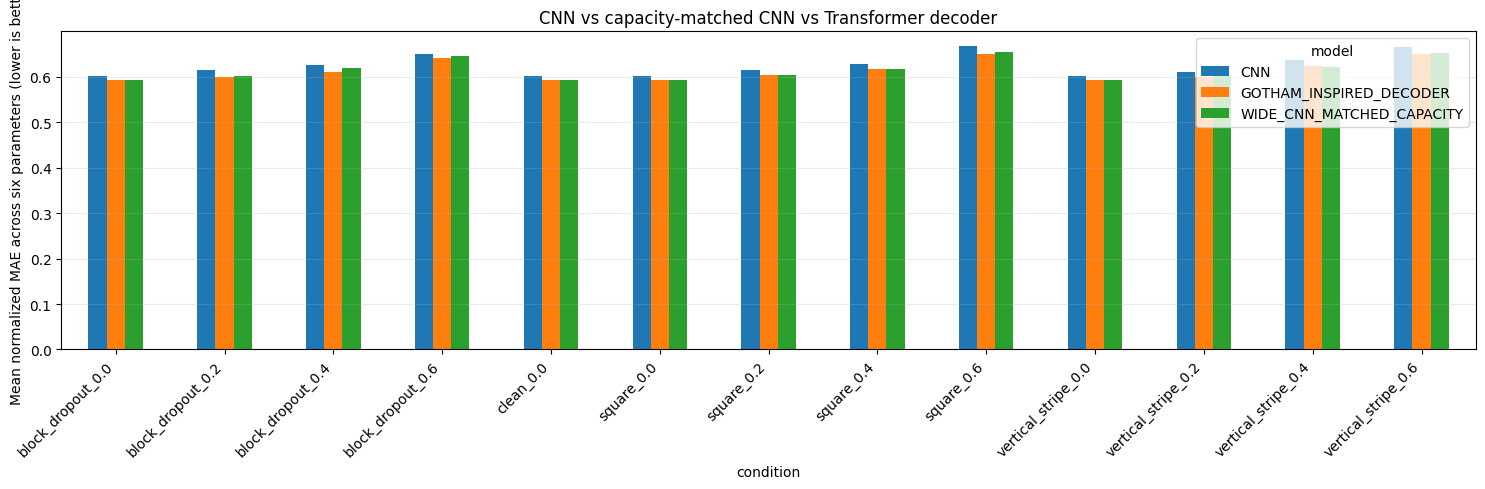


EXPERIMENT COMPLETE
Outputs:
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/training_summary.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/test_metrics_per_seed.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/test_metrics_seed_ensemble.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/paired_bootstrap_CI.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/overall_condition_summary.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/cnn_vs_gotham_inspired_transformer.png
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/run_manifest.json
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/CosmoTokens_Capacity_Matched_Results.xlsx
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/CosmoTokens_Capacity_Matched_CSVs.zip
Total elapsed: 0.36 hours

Created downloadable result files:
 - /conte

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Starting automatic download of CSV ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Interpretation guide:
 - Lower normalized_MAE is better.
 - In paired_bootstrap_CI.csv, negative delta_B_minus_A favours model_B over model_A.
 - If the 95% CI crosses zero, evidence for a performance difference is inconclusive.
 - Because this test set was previously examined, treat the results as exploratory.


In [ ]:
# =============================================================================
# COSMOTOKENS: STANDARD CNN vs PARAMETER-MATCHED CNN vs TRANSFORMER
# Google Colab, end-to-end training/evaluation
#
# Important scientific distinction:
# This adapts GOTHAM's architectural idea (CNN/residual encoder + Transformer
# decoder with cross-attention) to 2D CAMELS stellar-mass maps and six scalar
# regression targets. It is NOT a literal reproduction of GOTHAM: GOTHAM uses
# three 3D PM density fields and autoregressively generates tokenized halo
# catalogues. Six simultaneous scalar parameters do not require halo-token
# autoregressive decoding.
#
# Uses existing data and the existing simulation-level split. Trains a standard CNN, a wider approximately parameter-matched CNN, and the
# adapted Transformer under the same protocol. Test metrics are exploratory because the test set has been
# examined in previous CosmoTokens iterations.
# =============================================================================

import os, gc, json, time, random, math, warnings
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------- ROBUST GOOGLE DRIVE MOUNT ---------------------------
# Colab raises "Mountpoint must not already contain files" when drive.mount()
# is called on a non-empty directory that is not the intended mountpoint.
# First reuse an existing mount; otherwise choose an empty mountpoint.
from google.colab import drive

mount_candidates = [Path("/content/drive"), Path("/content/gdrive")]
mount_candidates += [Path(f"/content/gdrive{i}") for i in range(2, 10)]
MOUNTPOINT = None

for candidate in mount_candidates:
    # If Drive is already mounted here, reuse it without calling mount again.
    if (candidate / "MyDrive").exists():
        MOUNTPOINT = candidate
        print(f"Google Drive already available at: {MOUNTPOINT}")
        break

if MOUNTPOINT is None:
    for candidate in mount_candidates:
        if candidate.is_symlink():
            continue
        if not candidate.exists():
            candidate.mkdir(parents=True, exist_ok=True)
        # Only attempt to mount into an empty directory.
        if candidate.is_dir() and not any(candidate.iterdir()):
            MOUNTPOINT = candidate
            break

if MOUNTPOINT is None:
    raise RuntimeError(
        "Could not find an empty Google Drive mountpoint. "
        "In Colab, inspect /content and remove/rename only the accidental "
        "empty mount directory, or restart the runtime and rerun this cell."
    )

if not (MOUNTPOINT / "MyDrive").exists():
    drive.mount(str(MOUNTPOINT), force_remount=False)
    if not (MOUNTPOINT / "MyDrive").exists():
        raise RuntimeError(
            f"Drive mount did not expose MyDrive at {MOUNTPOINT}. "
            "Complete the Colab Drive authorization and rerun."
        )

# ------------------------------ CONFIG ---------------------------------------
ROOT = MOUNTPOINT / "MyDrive" / "CosmoTokens"
OUT = ROOT / "experiments" / "capacity_matched_v1"
CKPT_DIR = OUT / "checkpoints"
OUT.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [101, 202, 303]
PARAMS = ["Omega_m", "sigma_8", "A_SN1", "A_AGN1", "A_SN2", "A_AGN2"]
N_PARAMS = len(PARAMS)

MASK_LEVELS = [0.0, 0.2, 0.4, 0.6]
MASK_GEOMETRIES = ["square", "vertical_stripe", "block_dropout"]
VIEWS_PER_SIM_PER_EPOCH = 4
BATCH_SIZE = 64
MAX_EPOCHS = 60
PATIENCE = 10
MIN_DELTA = 1e-4
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
AMP = True

# Same robust validation conditions as the existing CosmoTokens v4 protocol.
VAL_CONDITIONS = [
    "clean_0.0", "square_0.4", "square_0.6",
    "vertical_stripe_0.4", "block_dropout_0.4"
]
TEST_CONDITIONS = ["clean_0.0"] + [
    f"{g}_{f:.1f}" for g in MASK_GEOMETRIES for f in MASK_LEVELS
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = AMP and DEVICE.type == "cuda"

print("=" * 76)
print("COSMOTOKENS — CAPACITY-MATCHED ARCHITECTURE COMPARISON")
print("=" * 76)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)
print("Seeds:", SEEDS)
print("Epoch cap:", MAX_EPOCHS)
print("Train simulations × views/epoch:", "800 ×", VIEWS_PER_SIM_PER_EPOCH)

# -------------------------- REPRODUCIBILITY ----------------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def amp_context():
    if USE_AMP:
        return torch.amp.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()

def make_scaler():
    return torch.amp.GradScaler("cuda", enabled=USE_AMP)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    info = torch.utils.data.get_worker_info()
    if info is not None and hasattr(info.dataset, "rng"):
        info.dataset.rng = np.random.default_rng(worker_seed)

# -------------------------- LOAD EXISTING DATA -------------------------------
# Drive was mounted safely above; ROOT now points to the mounted MyDrive.
manifest_path = ROOT / "artifacts" / "step1" / "step1_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError(f"Missing existing manifest: {manifest_path}")
with open(manifest_path, "r") as f:
    manifest = json.load(f)

MAP_FILE = ROOT / "data" / "processed" / "maps_Mstar_sum64_log1p.npy"
maps = np.load(MAP_FILE, mmap_mode="r", allow_pickle=False)
labels = np.load(manifest["labels_per_map_path"], mmap_mode="r", allow_pickle=False)
parent_ids = np.asarray(
    np.load(manifest["parent_simulation_id_path"], allow_pickle=False)
).reshape(-1).astype(np.int64)

SPLIT_DIR = ROOT / "data" / "splits"
train_sim_ids = np.load(SPLIT_DIR / "train_simulation_ids.npy", allow_pickle=False).astype(np.int64)
val_sim_ids = np.load(SPLIT_DIR / "validation_simulation_ids.npy", allow_pickle=False).astype(np.int64)
test_sim_ids = np.load(SPLIT_DIR / "test_simulation_ids.npy", allow_pickle=False).astype(np.int64)
train_idx = np.load(SPLIT_DIR / "train_map_indices.npy", allow_pickle=False).astype(np.int64)
val_idx = np.load(SPLIT_DIR / "validation_map_indices.npy", allow_pickle=False).astype(np.int64)
test_idx = np.load(SPLIT_DIR / "test_map_indices.npy", allow_pickle=False).astype(np.int64)

assert maps.shape == (15000, 64, 64), f"Unexpected map shape: {maps.shape}"
assert labels.shape == (15000, N_PARAMS), f"Unexpected labels shape: {labels.shape}"
assert len(parent_ids) == len(maps)
assert (len(train_sim_ids), len(val_sim_ids), len(test_sim_ids)) == (800, 100, 100)
assert (len(train_idx), len(val_idx), len(test_idx)) == (12000, 1500, 1500)
assert len(set(train_sim_ids) & set(val_sim_ids)) == 0
assert len(set(train_sim_ids) & set(test_sim_ids)) == 0
assert len(set(val_sim_ids) & set(test_sim_ids)) == 0

H, W = maps.shape[1:]
map_indices_by_sim = {
    int(sid): np.flatnonzero(parent_ids == sid)
    for sid in np.unique(parent_ids)
}
assert all(len(map_indices_by_sim[int(s)]) == 15 for s in np.unique(parent_ids))

# Compute target scaling using one label row per TRAIN simulation only.
sim_target = {}
for sid in np.unique(parent_ids):
    ix = map_indices_by_sim[int(sid)]
    rows = np.asarray(labels[ix], dtype=np.float64)
    if not np.allclose(rows, rows[0], rtol=1e-6, atol=1e-7):
        raise ValueError(f"Targets are not constant within simulation {sid}")
    sim_target[int(sid)] = rows[0]
train_target_rows = np.stack([sim_target[int(s)] for s in train_sim_ids])
target_mean = train_target_rows.mean(axis=0).astype(np.float32)
target_std = train_target_rows.std(axis=0).astype(np.float32)
target_std[target_std < 1e-12] = 1.0
Y_z = ((np.asarray(labels, dtype=np.float32) - target_mean) / target_std).astype(np.float32)

print("Loaded maps:", maps.shape)
print("Train/validation/test simulations:", len(train_sim_ids), len(val_sim_ids), len(test_sim_ids))
print("Target mean:", np.round(target_mean, 5))
print("Target std:", np.round(target_std, 5))
print("Note: test set has been used in previous project iterations; treat its results as exploratory.")

# ------------------------------ MASKS -----------------------------------------
def make_valid_mask(rng, geometry, fraction, h=64, w=64):
    valid = np.ones((h, w), dtype=np.bool_)
    if fraction <= 0:
        return valid
    target = int(round(fraction * h * w))
    if geometry == "square":
        side = max(1, min(h, w, int(round(np.sqrt(fraction) * min(h, w)))))
        y0 = int(rng.integers(0, h - side + 1))
        x0 = int(rng.integers(0, w - side + 1))
        valid[y0:y0+side, x0:x0+side] = False
    elif geometry == "vertical_stripe":
        sw = max(1, min(w, int(round(fraction * w))))
        x0 = int(rng.integers(0, w - sw + 1))
        valid[:, x0:x0+sw] = False
    elif geometry == "block_dropout":
        block = 8
        cells = [(y, x) for y in range(0, h, block) for x in range(0, w, block)]
        rng.shuffle(cells)
        removed = 0
        for y, x in cells:
            if removed >= target:
                break
            bh, bw = min(block, h-y), min(block, w-x)
            valid[y:y+bh, x:x+bw] = False
            removed += bh*bw
    else:
        raise ValueError(geometry)
    return valid

def parse_condition(condition):
    if condition == "clean_0.0":
        return "clean", 0.0
    geometry, frac = condition.rsplit("_", 1)
    return geometry, float(frac)

def make_fixed_mask_cache(map_indices, conditions, seed_offset):
    cache = {}
    for condition in conditions:
        geometry, fraction = parse_condition(condition)
        rng = np.random.default_rng(seed_offset + sum(map(ord, condition))*997)
        masks = np.ones((len(map_indices), H, W), dtype=np.bool_)
        if geometry != "clean" and fraction > 0:
            for j in range(len(map_indices)):
                masks[j] = make_valid_mask(rng, geometry, fraction, H, W)
        cache[condition] = masks
    return cache

val_mask_cache = make_fixed_mask_cache(val_idx, VAL_CONDITIONS, 41000)
test_mask_cache = make_fixed_mask_cache(test_idx, TEST_CONDITIONS, 91000)

# -------------------------- SIMULATION-BALANCED DATA --------------------------
class SimulationBalancedDataset(Dataset):
    def __init__(self, simulation_ids, seed=0):
        self.simulation_ids = np.asarray(simulation_ids, dtype=np.int64)
        self.virtual_sim_index = np.repeat(np.arange(len(self.simulation_ids)), VIEWS_PER_SIM_PER_EPOCH)
        self.rng = np.random.default_rng(seed)
    def __len__(self):
        return len(self.virtual_sim_index)
    def __getitem__(self, i):
        sid = int(self.simulation_ids[int(self.virtual_sim_index[i])])
        choices = map_indices_by_sim[sid]
        map_idx = int(choices[self.rng.integers(0, len(choices))])
        image = np.array(maps[map_idx], dtype=np.float32, copy=True)
        fraction = float(self.rng.choice(MASK_LEVELS))
        if fraction <= 0:
            valid = np.ones((H, W), dtype=np.bool_)
        else:
            geom = str(self.rng.choice(MASK_GEOMETRIES))
            valid = make_valid_mask(self.rng, geom, fraction, H, W)
        image[~valid] = 0.0
        x = np.stack([image, valid.astype(np.float32)], axis=0)
        return torch.from_numpy(x), torch.from_numpy(Y_z[map_idx].copy())

def make_loader(dataset, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0), worker_init_fn=seed_worker,
        generator=generator, drop_last=False
    )

# ------------------------------ MODELS ----------------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.skip = nn.Identity() if (in_ch == out_ch and stride == 1) else nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.bn2(self.conv2(self.act(self.bn1(self.conv1(x))))) + self.skip(x))

class CNNEncoder2D(nn.Module):
    """2D adaptation of the residual convolutional feature encoder."""
    def __init__(self, token_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            ConvBlock(2, 32, stride=2),    # 64 -> 32
            ConvBlock(32, 32),
            ConvBlock(32, 64, stride=2),   # 32 -> 16
            ConvBlock(64, 64),
            ConvBlock(64, 128, stride=2),  # 16 -> 8
            ConvBlock(128, 128),
            nn.Conv2d(128, token_dim, kernel_size=1),
        )
    def forward(self, x):
        feat = self.net(x)                         # B x 64 x 8 x 8
        tokens = feat.flatten(2).transpose(1, 2)  # B x 64 spatial tokens x 64 features
        return tokens

class CNNRegressor(nn.Module):
    """Original-width CNN baseline: 32/64/128/128 channels."""
    def __init__(self, n_params=6, width=32):
        super().__init__()
        c1, c2, c3 = width, 2 * width, 4 * width
        self.backbone = nn.Sequential(
            ConvBlock(2, c1, stride=2),
            ConvBlock(c1, c2, stride=2),
            ConvBlock(c2, c3, stride=2),
            ConvBlock(c3, c3),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(c3, c3), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(c3, n_params)
        )
    def forward(self, x):
        return self.head(self.backbone(x))

class WideCNNRegressor(CNNRegressor):
    """Wider CNN control; width=40 targets roughly the Transformer's capacity."""
    def __init__(self, n_params=6):
        super().__init__(n_params=n_params, width=40)

class GOTHAMInspiredDecoderRegressor(nn.Module):
    """
    GOTHAM-inspired structure for a different task:
    residual CNN encoder -> spatial memory tokens -> six learned parameter
    queries -> Transformer decoder with query self-attention and cross-attention.
    Unlike GOTHAM, this predicts all six scalar parameters simultaneously rather
    than autoregressively generating halo-property tokens.
    """
    def __init__(self, n_params=6, dim=64, n_heads=4, n_layers=4):
        super().__init__()
        self.encoder = CNNEncoder2D(token_dim=dim)
        self.memory_norm = nn.LayerNorm(dim)
        self.query = nn.Parameter(torch.randn(1, n_params, dim) * 0.02)
        self.query_pos = nn.Parameter(torch.randn(1, n_params, dim) * 0.02)
        layer = nn.TransformerDecoderLayer(
            d_model=dim, nhead=n_heads, dim_feedforward=dim*4,
            dropout=0.1, activation="gelu", batch_first=True, norm_first=True
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=n_layers)
        self.output_norm = nn.LayerNorm(dim)
        self.regression_heads = nn.ModuleList([
            nn.Sequential(nn.Linear(dim, 32), nn.GELU(), nn.Dropout(0.1), nn.Linear(32, 1))
            for _ in range(n_params)
        ])
    def forward(self, x):
        memory = self.memory_norm(self.encoder(x))
        q = (self.query + self.query_pos).expand(x.shape[0], -1, -1)
        decoded = self.decoder(tgt=q, memory=memory)  # self-attention + cross-attention
        decoded = self.output_norm(decoded)
        return torch.cat([head(decoded[:, i, :]) for i, head in enumerate(self.regression_heads)], dim=1)

def n_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ------------------------------ EVALUATION ------------------------------------
@torch.no_grad()
def predict_map_indices(model, map_indices, valid_masks=None, batch_size=128):
    model.eval()
    outputs = []
    for start in range(0, len(map_indices), batch_size):
        ids = map_indices[start:start+batch_size]
        imgs = np.asarray(maps[ids], dtype=np.float32).copy()
        if valid_masks is None:
            valid = np.ones_like(imgs, dtype=np.bool_)
        else:
            valid = valid_masks[start:start+len(ids)]
        imgs[~valid] = 0.0
        x = np.stack([imgs, valid.astype(np.float32)], axis=1)
        xt = torch.from_numpy(x).to(DEVICE, non_blocking=True)
        with amp_context():
            pred = model(xt)
        outputs.append(pred.float().cpu().numpy())
    return np.concatenate(outputs, axis=0)

def aggregate_by_simulation(map_indices, predictions_z):
    sims = parent_ids[map_indices]
    unique_sims = np.unique(sims)
    pred_agg, true_agg = [], []
    for sid in unique_sims:
        sel = sims == sid
        pred_agg.append(predictions_z[sel].mean(axis=0))
        true_agg.append(np.asarray(labels[map_indices[sel]], dtype=np.float32).mean(axis=0))
    return unique_sims, np.stack(true_agg), np.stack(pred_agg)

def validation_score(model):
    scores = []
    for condition in VAL_CONDITIONS:
        masks = val_mask_cache[condition]
        pred_z = predict_map_indices(model, val_idx, masks)
        _, true_raw, pred_z_agg = aggregate_by_simulation(val_idx, pred_z)
        true_z = (true_raw - target_mean) / target_std
        scores.append(np.mean(np.abs(pred_z_agg - true_z)))
    return float(np.mean(scores))

@torch.no_grad()
def evaluate_condition(model, map_indices, masks):
    pred_z = predict_map_indices(model, map_indices, masks)
    sim_ids, true_raw, pred_z_agg = aggregate_by_simulation(map_indices, pred_z)
    true_z = (true_raw - target_mean) / target_std
    pred_raw = pred_z_agg * target_std + target_mean
    true_raw = true_z * target_std + target_mean
    rows = []
    for j, name in enumerate(PARAMS):
        err_z = pred_z_agg[:, j] - true_z[:, j]
        err_raw = pred_raw[:, j] - true_raw[:, j]
        rows.append({
            "parameter": name,
            "n_simulations": len(sim_ids),
            "normalized_MAE": float(np.mean(np.abs(err_z))),
            "normalized_RMSE": float(np.sqrt(np.mean(err_z**2))),
            "physical_MAE": float(np.mean(np.abs(err_raw))),
            "physical_RMSE": float(np.sqrt(np.mean(err_raw**2))),
            "bias_physical": float(np.mean(err_raw)),
            "prediction_std_ratio": float(np.std(pred_z_agg[:, j]) / max(np.std(true_z[:, j]), 1e-12)),
            "R2_standardized": float(1 - np.sum(err_z**2) / max(np.sum((true_z[:, j]-true_z[:, j].mean())**2), 1e-12))
        })
    return rows, (sim_ids, true_z, pred_z_agg)

# ------------------------------ TRAINING ---------------------------------------
def train_one(model_name, model_class, seed, train_loader):
    set_seed(seed)
    model = model_class(n_params=N_PARAMS).to(DEVICE)
    print(f"\n{model_name} seed={seed}: {n_parameters(model):,} trainable parameters")
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
    scaler = make_scaler()
    best_score = float("inf")
    best_epoch = 0
    wait = 0
    best_path = CKPT_DIR / f"{model_name}_seed{seed}_best.pt"
    history = []
    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_context():
                pred = model(xb)
                loss = nn.functional.mse_loss(pred, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            train_losses.append(float(loss.detach().cpu()))
        val_score = validation_score(model)
        scheduler.step(val_score)
        history.append({
            "model": model_name, "seed": seed, "epoch": epoch,
            "train_mse": float(np.mean(train_losses)), "robust_val_normalized_MAE": val_score,
            "learning_rate": optimizer.param_groups[0]["lr"]
        })
        print(f"{model_name} seed={seed} epoch={epoch:02d} "
              f"train_MSE={np.mean(train_losses):.4f} val_score={val_score:.4f}")
        if val_score < best_score - MIN_DELTA:
            best_score, best_epoch, wait = val_score, epoch, 0
            torch.save({
                "model_name": model_name, "seed": seed, "epoch": epoch,
                "model_state_dict": model.state_dict(), "validation_score": best_score,
                "target_mean": target_mean.tolist(), "target_std": target_std.tolist()
            }, best_path)
        else:
            wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}; best epoch={best_epoch}")
            break

    hist_path = OUT / f"{model_name}_seed{seed}_history.csv"
    pd.DataFrame(history).to_csv(hist_path, index=False)
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Finished {model_name} seed={seed}: best epoch={best_epoch}, "
          f"score={best_score:.4f}, elapsed={(time.time()-start_time)/60:.1f} min")
    del optimizer, scheduler, scaler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, best_epoch, best_score

# ------------------------------ RUN EXPERIMENT --------------------------------
train_models = {
    "CNN": CNNRegressor,
    "WIDE_CNN_MATCHED_CAPACITY": WideCNNRegressor,
    "GOTHAM_INSPIRED_DECODER": GOTHAMInspiredDecoderRegressor
}

# Report parameter counts before training; the wider CNN is a capacity control.
parameter_counts = {name: n_parameters(cls(n_params=N_PARAMS)) for name, cls in train_models.items()}
print("\nTrainable parameter counts:")
for name, count in parameter_counts.items():
    print(f"  {name}: {count:,}")
print(f"  Wide CNN vs Transformer parameter difference: {100*abs(parameter_counts['WIDE_CNN_MATCHED_CAPACITY']-parameter_counts['GOTHAM_INSPIRED_DECODER'])/parameter_counts['GOTHAM_INSPIRED_DECODER']:.1f}%")
all_models = {}
training_summary = []
all_histories = []

experiment_start = time.time()
for model_name, model_class in train_models.items():
    for seed in SEEDS:
        # Fresh, deterministic simulation-balanced training dataset for each run.
        set_seed(seed)
        train_ds = SimulationBalancedDataset(train_sim_ids, seed=seed)
        loader = make_loader(train_ds, seed)
        model, best_epoch, best_score = train_one(model_name, model_class, seed, loader)
        all_models[(model_name, seed)] = model
        training_summary.append({
            "model": model_name, "seed": seed, "best_epoch": best_epoch,
            "best_robust_val_normalized_MAE": best_score
        })
        del loader, train_ds
        gc.collect()

training_summary_df = pd.DataFrame(training_summary)
training_summary_df.to_csv(OUT / "training_summary.csv", index=False)
print("\nTraining summary:")
display(training_summary_df)

# ------------------------------ TEST / EXPLORATORY EVALUATION -----------------
# The existing test set has been used in earlier development, so these results
# are exploratory rather than a pristine confirmatory benchmark.
metric_rows = []
prediction_store = {}

for model_name in train_models:
    for seed in SEEDS:
        model = all_models[(model_name, seed)]
        for condition in TEST_CONDITIONS:
            rows, pred_obj = evaluate_condition(model, test_idx, test_mask_cache[condition])
            for row in rows:
                metric_rows.append({"model": model_name, "seed": seed, "condition": condition, **row})
            prediction_store[(model_name, seed, condition)] = pred_obj
        print(f"Evaluated {model_name} seed={seed}")
        model.cpu()
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(OUT / "test_metrics_per_seed.csv", index=False)

# Ensemble predictions across seeds: average predictions per simulation first,
# then calculate metrics. This is more meaningful than averaging MAEs.
ensemble_rows = []
ensemble_predictions = {}
for model_name in train_models:
    for condition in TEST_CONDITIONS:
        seed_objects = [prediction_store[(model_name, seed, condition)] for seed in SEEDS]
        sim_ids = seed_objects[0][0]
        assert all(np.array_equal(sim_ids, o[0]) for o in seed_objects)
        true_z = seed_objects[0][1]
        pred_z = np.mean(np.stack([o[2] for o in seed_objects], axis=0), axis=0)
        pred_raw = pred_z * target_std + target_mean
        true_raw = true_z * target_std + target_mean
        ensemble_predictions[(model_name, condition)] = (sim_ids, true_z, pred_z)
        for j, name in enumerate(PARAMS):
            ez = pred_z[:, j] - true_z[:, j]
            er = pred_raw[:, j] - true_raw[:, j]
            ensemble_rows.append({
                "model": model_name, "condition": condition, "parameter": name,
                "n_simulations": len(sim_ids),
                "normalized_MAE": float(np.mean(np.abs(ez))),
                "normalized_RMSE": float(np.sqrt(np.mean(ez**2))),
                "physical_MAE": float(np.mean(np.abs(er))),
                "physical_RMSE": float(np.sqrt(np.mean(er**2))),
                "bias_physical": float(np.mean(er)),
                "prediction_std_ratio": float(np.std(pred_z[:, j]) / max(np.std(true_z[:, j]), 1e-12)),
                "R2_standardized": float(1 - np.sum(ez**2) / max(np.sum((true_z[:, j]-true_z[:, j].mean())**2), 1e-12))
            })

ensemble_df = pd.DataFrame(ensemble_rows)
ensemble_df.to_csv(OUT / "test_metrics_seed_ensemble.csv", index=False)

# Paired simulation-level bootstrap CIs for all pairwise model differences.
# delta = model B MAE - model A MAE; negative favours model B.
rng = np.random.default_rng(20261014)
boot_rows = []
model_names = list(train_models.keys())
for i in range(len(model_names)):
    for j_model in range(i + 1, len(model_names)):
        model_a, model_b = model_names[i], model_names[j_model]
        for condition in TEST_CONDITIONS:
            a_obj = ensemble_predictions[(model_a, condition)]
            b_obj = ensemble_predictions[(model_b, condition)]
            assert np.array_equal(a_obj[0], b_obj[0])
            true_z = a_obj[1]
            a_pred, b_pred = a_obj[2], b_obj[2]
            for j, name in enumerate(PARAMS):
                a_err = np.abs(a_pred[:, j] - true_z[:, j])
                b_err = np.abs(b_pred[:, j] - true_z[:, j])
                delta_per_sim = b_err - a_err
                boots = np.empty(2000, dtype=np.float32)
                n = len(delta_per_sim)
                for b in range(len(boots)):
                    ii = rng.integers(0, n, size=n)
                    boots[b] = delta_per_sim[ii].mean()
                boot_rows.append({
                    "model_A": model_a, "model_B": model_b,
                    "delta_definition": "model_B normalized absolute error minus model_A; negative favours model_B",
                    "condition": condition, "parameter": name,
                    "n_simulations": n,
                    "delta_B_minus_A_normalized_MAE": float(delta_per_sim.mean()),
                    "CI95_low": float(np.quantile(boots, 0.025)),
                    "CI95_high": float(np.quantile(boots, 0.975)),
                    "fraction_bootstrap_below_zero": float(np.mean(boots < 0))
                })
boot_df = pd.DataFrame(boot_rows)
boot_df.to_csv(OUT / "paired_bootstrap_CI.csv", index=False)

# Primary overall summary: mean normalized MAE across six parameters for each condition.
overall = (
    ensemble_df.groupby(["model", "condition"])["normalized_MAE"]
    .mean().reset_index(name="mean_normalized_MAE_across_parameters")
)
overall.to_csv(OUT / "overall_condition_summary.csv", index=False)

# Plot mean normalized MAE by condition and architecture.
pivot = overall.pivot(index="condition", columns="model", values="mean_normalized_MAE_across_parameters")
ax = pivot.plot(kind="bar", figsize=(15, 5))
ax.set_ylabel("Mean normalized MAE across six parameters (lower is better)")
ax.set_title("CNN vs capacity-matched CNN vs Transformer decoder")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plot_path = OUT / "cnn_vs_gotham_inspired_transformer.png"
plt.savefig(plot_path, dpi=180)
plt.show()

# Save run manifest and a compact interpretation aid.
run_manifest = {
    "experiment": "CosmoTokens standard CNN vs capacity-matched CNN vs GOTHAM-inspired Transformer decoder",
    "trainable_parameter_counts": parameter_counts,
    "capacity_control_note": "Wide CNN uses width=40 (channels 40/80/160/160) and is compared with the Transformer to test whether extra parameter capacity explains any gains.",
    "gotham_repository": "https://github.com/shivampcosmo/GOTHAM",
    "adaptation_note": (
        "Not an exact GOTHAM reproduction. GOTHAM uses three 3D PM density fields "
        "and autoregressive halo-property token generation. This experiment uses "
        "2D CAMELS stellar-mass maps and simultaneous six-parameter regression."
    ),
    "root": str(ROOT), "output": str(OUT), "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE,
    "train_simulations": train_sim_ids.tolist(),
    "validation_simulations": val_sim_ids.tolist(),
    "test_simulations": test_sim_ids.tolist(),
    "target_names": PARAMS,
    "target_mean_train_only": target_mean.tolist(),
    "target_std_train_only": target_std.tolist(),
    "test_set_caveat": "Test set was used during earlier project iterations; results are exploratory."
}
with open(OUT / "run_manifest.json", "w") as f:
    json.dump(run_manifest, f, indent=2)

print("\n" + "="*76)
print("EXPERIMENT COMPLETE")
print("Outputs:")
for p in [
    OUT / "training_summary.csv",
    OUT / "test_metrics_per_seed.csv",
    OUT / "test_metrics_seed_ensemble.csv",
    OUT / "paired_bootstrap_CI.csv",
    OUT / "overall_condition_summary.csv",
    plot_path,
    OUT / "run_manifest.json",
    OUT / "CosmoTokens_Capacity_Matched_Results.xlsx",
    OUT / "CosmoTokens_Capacity_Matched_CSVs.zip",
]:
    print(" -", p)
print(f"Total elapsed: {(time.time()-experiment_start)/3600:.2f} hours")
# Automatically bundle all result tables into one Excel workbook and a ZIP of CSVs.
import zipfile
csv_names = [
    "training_summary.csv", "test_metrics_per_seed.csv",
    "test_metrics_seed_ensemble.csv", "paired_bootstrap_CI.csv",
    "overall_condition_summary.csv"
]
excel_path = OUT / "CosmoTokens_Capacity_Matched_Results.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for filename in csv_names:
        p = OUT / filename
        if p.exists():
            pd.read_csv(p).to_excel(writer, sheet_name=Path(filename).stem[:31], index=False)
zip_path = OUT / "CosmoTokens_Capacity_Matched_CSVs.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for filename in csv_names:
        p = OUT / filename
        if p.exists():
            zf.write(p, arcname=p.name)
print("\nCreated downloadable result files:")
print(" -", excel_path)
print(" -", zip_path)
try:
    from google.colab import files as colab_files
    print("Starting automatic download of Excel workbook...")
    colab_files.download(str(excel_path))
    print("Starting automatic download of CSV ZIP...")
    colab_files.download(str(zip_path))
except Exception as exc:
    print("Automatic browser download unavailable; files are saved in Drive.", repr(exc))

print("\nInterpretation guide:")
print(" - Lower normalized_MAE is better.")
print(" - In paired_bootstrap_CI.csv, negative delta_B_minus_A favours model_B over model_A.")
print(" - If the 95% CI crosses zero, evidence for a performance difference is inconclusive.")
print(" - Because this test set was previously examined, treat the results as exploratory.")

In [ ]:

from google.colab import files
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/CosmoTokens/experiments/"
    "capacity_matched_v1/CosmoTokens_Capacity_Matched_Results.xlsx"
)

assert path.exists(), f"Workbook not found: {path}"
files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Google Drive already available at: /content/drive
COSMOTOKENS — CAPACITY-MATCHED ARCHITECTURE COMPARISON
Device: cuda
GPU: Tesla T4
Output: /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1
Seeds: [101, 202, 303]
Epoch cap: 60
Train simulations × views/epoch: 800 × 4
Loaded maps: (15000, 64, 64)
Train/validation/test simulations: 800 100 100
Target mean: [0.29881 0.79787 1.37286 1.33537 1.08712 1.09251]
Target std: [0.11643 0.11651 1.04214 1.01402 0.42652 0.43204]
Note: test set has been used in previous project iterations; treat its results as exploratory.

Trainable parameter counts:
  CNN: 610,630
  WIDE_CNN_MATCHED_CAPACITY: 953,046
  GOTHAM_INSPIRED_DECODER: 974,854
  Wide CNN vs Transformer parameter difference: 2.2%

CNN seed=101: 610,630 trainable parameters
CNN seed=101 epoch=01 train_MSE=0.9294 val_score=0.7667
CNN seed=101 epoch=02 train_MSE=0.8644 val_score=0.7141
CNN seed=101 epoch=03 train_MSE=0.8368 val_score=0.7061
CNN seed=101 epoch=04 train_MSE=0.8234

,model,seed,best_epoch,best_robust_val_normalized_MAE
0,CNN,101,24,0.629792
1,CNN,202,27,0.628598
2,CNN,303,55,0.624725
3,WIDE_CNN_MATCHED_CAPACITY,101,35,0.612700
4,WIDE_CNN_MATCHED_CAPACITY,202,49,0.614362
5,WIDE_CNN_MATCHED_CAPACITY,303,55,0.613311
6,GOTHAM_INSPIRED_DECODER,101,57,0.607165
7,GOTHAM_INSPIRED_DECODER,202,49,0.618925
8,GOTHAM_INSPIRED_DECODER,303,48,0.610760


Evaluated CNN seed=101
Evaluated CNN seed=202
Evaluated CNN seed=303
Evaluated WIDE_CNN_MATCHED_CAPACITY seed=101
Evaluated WIDE_CNN_MATCHED_CAPACITY seed=202
Evaluated WIDE_CNN_MATCHED_CAPACITY seed=303
Evaluated GOTHAM_INSPIRED_DECODER seed=101
Evaluated GOTHAM_INSPIRED_DECODER seed=202
Evaluated GOTHAM_INSPIRED_DECODER seed=303


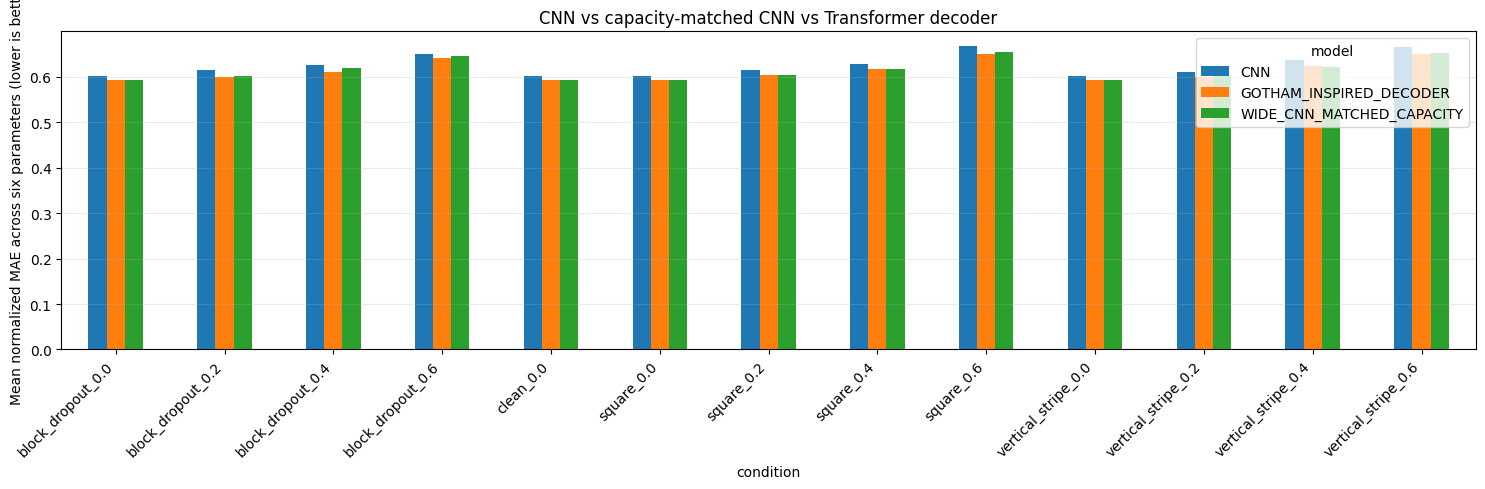


EXPERIMENT COMPLETE
Outputs:
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/training_summary.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/test_metrics_per_seed.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/test_metrics_seed_ensemble.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/test_simulation_predictions.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/paired_bootstrap_CI.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/overall_paired_bootstrap_CI.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/overall_condition_summary.csv
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/cnn_vs_gotham_inspired_transformer.png
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/run_manifest.json
 - /content/drive/MyDrive/CosmoTokens/experiments/capacity_matched_v1/CosmoTokens_Capac

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Starting automatic download of CSV ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Interpretation guide:
 - Lower normalized_MAE is better.
 - In paired_bootstrap_CI.csv, negative delta_B_minus_A favours model_B over model_A.
 - If the 95% CI crosses zero, evidence for a performance difference is inconclusive.
 - Because this test set was previously examined, treat the results as exploratory.


In [ ]:
# =============================================================================
# COSMOTOKENS: STANDARD CNN vs PARAMETER-MATCHED CNN vs TRANSFORMER
# Google Colab, end-to-end training/evaluation
#
# Important scientific distinction:
# This adapts GOTHAM's architectural idea (CNN/residual encoder + Transformer
# decoder with cross-attention) to 2D CAMELS stellar-mass maps and six scalar
# regression targets. It is NOT a literal reproduction of GOTHAM: GOTHAM uses
# three 3D PM density fields and autoregressively generates tokenized halo
# catalogues. Six simultaneous scalar parameters do not require halo-token
# autoregressive decoding.
#
# Uses existing data and the existing simulation-level split. Trains a standard CNN, a wider approximately parameter-matched CNN, and the
# adapted Transformer under the same protocol. Test metrics are exploratory because the test set has been
# examined in previous CosmoTokens iterations.
# =============================================================================

import os, gc, json, time, random, math, warnings
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------- ROBUST GOOGLE DRIVE MOUNT ---------------------------
# Colab raises "Mountpoint must not already contain files" when drive.mount()
# is called on a non-empty directory that is not the intended mountpoint.
# First reuse an existing mount; otherwise choose an empty mountpoint.
from google.colab import drive

mount_candidates = [Path("/content/drive"), Path("/content/gdrive")]
mount_candidates += [Path(f"/content/gdrive{i}") for i in range(2, 10)]
MOUNTPOINT = None

for candidate in mount_candidates:
    # If Drive is already mounted here, reuse it without calling mount again.
    if (candidate / "MyDrive").exists():
        MOUNTPOINT = candidate
        print(f"Google Drive already available at: {MOUNTPOINT}")
        break

if MOUNTPOINT is None:
    for candidate in mount_candidates:
        if candidate.is_symlink():
            continue
        if not candidate.exists():
            candidate.mkdir(parents=True, exist_ok=True)
        # Only attempt to mount into an empty directory.
        if candidate.is_dir() and not any(candidate.iterdir()):
            MOUNTPOINT = candidate
            break

if MOUNTPOINT is None:
    raise RuntimeError(
        "Could not find an empty Google Drive mountpoint. "
        "In Colab, inspect /content and remove/rename only the accidental "
        "empty mount directory, or restart the runtime and rerun this cell."
    )

if not (MOUNTPOINT / "MyDrive").exists():
    drive.mount(str(MOUNTPOINT), force_remount=False)
    if not (MOUNTPOINT / "MyDrive").exists():
        raise RuntimeError(
            f"Drive mount did not expose MyDrive at {MOUNTPOINT}. "
            "Complete the Colab Drive authorization and rerun."
        )

# ------------------------------ CONFIG ---------------------------------------
ROOT = MOUNTPOINT / "MyDrive" / "CosmoTokens"
OUT = ROOT / "experiments" / "capacity_matched_v1"
CKPT_DIR = OUT / "checkpoints"
OUT.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [101, 202, 303]
PARAMS = ["Omega_m", "sigma_8", "A_SN1", "A_AGN1", "A_SN2", "A_AGN2"]
N_PARAMS = len(PARAMS)

MASK_LEVELS = [0.0, 0.2, 0.4, 0.6]
MASK_GEOMETRIES = ["square", "vertical_stripe", "block_dropout"]
VIEWS_PER_SIM_PER_EPOCH = 4
BATCH_SIZE = 64
MAX_EPOCHS = 60
PATIENCE = 10
MIN_DELTA = 1e-4
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
AMP = True

# Same robust validation conditions as the existing CosmoTokens v4 protocol.
VAL_CONDITIONS = [
    "clean_0.0", "square_0.4", "square_0.6",
    "vertical_stripe_0.4", "block_dropout_0.4"
]
TEST_CONDITIONS = ["clean_0.0"] + [
    f"{g}_{f:.1f}" for g in MASK_GEOMETRIES for f in MASK_LEVELS
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = AMP and DEVICE.type == "cuda"

print("=" * 76)
print("COSMOTOKENS — CAPACITY-MATCHED ARCHITECTURE COMPARISON")
print("=" * 76)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Output:", OUT)
print("Seeds:", SEEDS)
print("Epoch cap:", MAX_EPOCHS)
print("Train simulations × views/epoch:", "800 ×", VIEWS_PER_SIM_PER_EPOCH)

# -------------------------- REPRODUCIBILITY ----------------------------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def amp_context():
    if USE_AMP:
        return torch.amp.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()

def make_scaler():
    return torch.amp.GradScaler("cuda", enabled=USE_AMP)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    info = torch.utils.data.get_worker_info()
    if info is not None and hasattr(info.dataset, "rng"):
        info.dataset.rng = np.random.default_rng(worker_seed)

# -------------------------- LOAD EXISTING DATA -------------------------------
# Drive was mounted safely above; ROOT now points to the mounted MyDrive.
manifest_path = ROOT / "artifacts" / "step1" / "step1_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError(f"Missing existing manifest: {manifest_path}")
with open(manifest_path, "r") as f:
    manifest = json.load(f)

MAP_FILE = ROOT / "data" / "processed" / "maps_Mstar_sum64_log1p.npy"
maps = np.load(MAP_FILE, mmap_mode="r", allow_pickle=False)
labels = np.load(manifest["labels_per_map_path"], mmap_mode="r", allow_pickle=False)
parent_ids = np.asarray(
    np.load(manifest["parent_simulation_id_path"], allow_pickle=False)
).reshape(-1).astype(np.int64)

SPLIT_DIR = ROOT / "data" / "splits"
train_sim_ids = np.load(SPLIT_DIR / "train_simulation_ids.npy", allow_pickle=False).astype(np.int64)
val_sim_ids = np.load(SPLIT_DIR / "validation_simulation_ids.npy", allow_pickle=False).astype(np.int64)
test_sim_ids = np.load(SPLIT_DIR / "test_simulation_ids.npy", allow_pickle=False).astype(np.int64)
train_idx = np.load(SPLIT_DIR / "train_map_indices.npy", allow_pickle=False).astype(np.int64)
val_idx = np.load(SPLIT_DIR / "validation_map_indices.npy", allow_pickle=False).astype(np.int64)
test_idx = np.load(SPLIT_DIR / "test_map_indices.npy", allow_pickle=False).astype(np.int64)

assert maps.shape == (15000, 64, 64), f"Unexpected map shape: {maps.shape}"
assert labels.shape == (15000, N_PARAMS), f"Unexpected labels shape: {labels.shape}"
assert len(parent_ids) == len(maps)
assert (len(train_sim_ids), len(val_sim_ids), len(test_sim_ids)) == (800, 100, 100)
assert (len(train_idx), len(val_idx), len(test_idx)) == (12000, 1500, 1500)
assert len(set(train_sim_ids) & set(val_sim_ids)) == 0
assert len(set(train_sim_ids) & set(test_sim_ids)) == 0
assert len(set(val_sim_ids) & set(test_sim_ids)) == 0

H, W = maps.shape[1:]
map_indices_by_sim = {
    int(sid): np.flatnonzero(parent_ids == sid)
    for sid in np.unique(parent_ids)
}
assert all(len(map_indices_by_sim[int(s)]) == 15 for s in np.unique(parent_ids))

# Compute target scaling using one label row per TRAIN simulation only.
sim_target = {}
for sid in np.unique(parent_ids):
    ix = map_indices_by_sim[int(sid)]
    rows = np.asarray(labels[ix], dtype=np.float64)
    if not np.allclose(rows, rows[0], rtol=1e-6, atol=1e-7):
        raise ValueError(f"Targets are not constant within simulation {sid}")
    sim_target[int(sid)] = rows[0]
train_target_rows = np.stack([sim_target[int(s)] for s in train_sim_ids])
target_mean = train_target_rows.mean(axis=0).astype(np.float32)
target_std = train_target_rows.std(axis=0).astype(np.float32)
target_std[target_std < 1e-12] = 1.0
Y_z = ((np.asarray(labels, dtype=np.float32) - target_mean) / target_std).astype(np.float32)

print("Loaded maps:", maps.shape)
print("Train/validation/test simulations:", len(train_sim_ids), len(val_sim_ids), len(test_sim_ids))
print("Target mean:", np.round(target_mean, 5))
print("Target std:", np.round(target_std, 5))
print("Note: test set has been used in previous project iterations; treat its results as exploratory.")

# ------------------------------ MASKS -----------------------------------------
def make_valid_mask(rng, geometry, fraction, h=64, w=64):
    valid = np.ones((h, w), dtype=np.bool_)
    if fraction <= 0:
        return valid
    target = int(round(fraction * h * w))
    if geometry == "square":
        side = max(1, min(h, w, int(round(np.sqrt(fraction) * min(h, w)))))
        y0 = int(rng.integers(0, h - side + 1))
        x0 = int(rng.integers(0, w - side + 1))
        valid[y0:y0+side, x0:x0+side] = False
    elif geometry == "vertical_stripe":
        sw = max(1, min(w, int(round(fraction * w))))
        x0 = int(rng.integers(0, w - sw + 1))
        valid[:, x0:x0+sw] = False
    elif geometry == "block_dropout":
        block = 8
        cells = [(y, x) for y in range(0, h, block) for x in range(0, w, block)]
        rng.shuffle(cells)
        removed = 0
        for y, x in cells:
            if removed >= target:
                break
            bh, bw = min(block, h-y), min(block, w-x)
            valid[y:y+bh, x:x+bw] = False
            removed += bh*bw
    else:
        raise ValueError(geometry)
    return valid

def parse_condition(condition):
    if condition == "clean_0.0":
        return "clean", 0.0
    geometry, frac = condition.rsplit("_", 1)
    return geometry, float(frac)

def make_fixed_mask_cache(map_indices, conditions, seed_offset):
    cache = {}
    for condition in conditions:
        geometry, fraction = parse_condition(condition)
        rng = np.random.default_rng(seed_offset + sum(map(ord, condition))*997)
        masks = np.ones((len(map_indices), H, W), dtype=np.bool_)
        if geometry != "clean" and fraction > 0:
            for j in range(len(map_indices)):
                masks[j] = make_valid_mask(rng, geometry, fraction, H, W)
        cache[condition] = masks
    return cache

val_mask_cache = make_fixed_mask_cache(val_idx, VAL_CONDITIONS, 41000)
test_mask_cache = make_fixed_mask_cache(test_idx, TEST_CONDITIONS, 91000)

# -------------------------- SIMULATION-BALANCED DATA --------------------------
class SimulationBalancedDataset(Dataset):
    def __init__(self, simulation_ids, seed=0):
        self.simulation_ids = np.asarray(simulation_ids, dtype=np.int64)
        self.virtual_sim_index = np.repeat(np.arange(len(self.simulation_ids)), VIEWS_PER_SIM_PER_EPOCH)
        self.rng = np.random.default_rng(seed)
    def __len__(self):
        return len(self.virtual_sim_index)
    def __getitem__(self, i):
        sid = int(self.simulation_ids[int(self.virtual_sim_index[i])])
        choices = map_indices_by_sim[sid]
        map_idx = int(choices[self.rng.integers(0, len(choices))])
        image = np.array(maps[map_idx], dtype=np.float32, copy=True)
        fraction = float(self.rng.choice(MASK_LEVELS))
        if fraction <= 0:
            valid = np.ones((H, W), dtype=np.bool_)
        else:
            geom = str(self.rng.choice(MASK_GEOMETRIES))
            valid = make_valid_mask(self.rng, geom, fraction, H, W)
        image[~valid] = 0.0
        x = np.stack([image, valid.astype(np.float32)], axis=0)
        return torch.from_numpy(x), torch.from_numpy(Y_z[map_idx].copy())

def make_loader(dataset, seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0), worker_init_fn=seed_worker,
        generator=generator, drop_last=False
    )

# ------------------------------ MODELS ----------------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.skip = nn.Identity() if (in_ch == out_ch and stride == 1) else nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        self.act = nn.GELU()
    def forward(self, x):
        return self.act(self.bn2(self.conv2(self.act(self.bn1(self.conv1(x))))) + self.skip(x))

class CNNEncoder2D(nn.Module):
    """2D adaptation of the residual convolutional feature encoder."""
    def __init__(self, token_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            ConvBlock(2, 32, stride=2),    # 64 -> 32
            ConvBlock(32, 32),
            ConvBlock(32, 64, stride=2),   # 32 -> 16
            ConvBlock(64, 64),
            ConvBlock(64, 128, stride=2),  # 16 -> 8
            ConvBlock(128, 128),
            nn.Conv2d(128, token_dim, kernel_size=1),
        )
    def forward(self, x):
        feat = self.net(x)                         # B x 64 x 8 x 8
        tokens = feat.flatten(2).transpose(1, 2)  # B x 64 spatial tokens x 64 features
        return tokens

class CNNRegressor(nn.Module):
    """Original-width CNN baseline: 32/64/128/128 channels."""
    def __init__(self, n_params=6, width=32):
        super().__init__()
        c1, c2, c3 = width, 2 * width, 4 * width
        self.backbone = nn.Sequential(
            ConvBlock(2, c1, stride=2),
            ConvBlock(c1, c2, stride=2),
            ConvBlock(c2, c3, stride=2),
            ConvBlock(c3, c3),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(c3, c3), nn.GELU(), nn.Dropout(0.15),
            nn.Linear(c3, n_params)
        )
    def forward(self, x):
        return self.head(self.backbone(x))

class WideCNNRegressor(CNNRegressor):
    """Wider CNN control; width=40 targets roughly the Transformer's capacity."""
    def __init__(self, n_params=6):
        super().__init__(n_params=n_params, width=40)

class GOTHAMInspiredDecoderRegressor(nn.Module):
    """
    GOTHAM-inspired structure for a different task:
    residual CNN encoder -> spatial memory tokens -> six learned parameter
    queries -> Transformer decoder with query self-attention and cross-attention.
    Unlike GOTHAM, this predicts all six scalar parameters simultaneously rather
    than autoregressively generating halo-property tokens.
    """
    def __init__(self, n_params=6, dim=64, n_heads=4, n_layers=4):
        super().__init__()
        self.encoder = CNNEncoder2D(token_dim=dim)
        self.memory_norm = nn.LayerNorm(dim)
        self.query = nn.Parameter(torch.randn(1, n_params, dim) * 0.02)
        self.query_pos = nn.Parameter(torch.randn(1, n_params, dim) * 0.02)
        layer = nn.TransformerDecoderLayer(
            d_model=dim, nhead=n_heads, dim_feedforward=dim*4,
            dropout=0.1, activation="gelu", batch_first=True, norm_first=True
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=n_layers)
        self.output_norm = nn.LayerNorm(dim)
        self.regression_heads = nn.ModuleList([
            nn.Sequential(nn.Linear(dim, 32), nn.GELU(), nn.Dropout(0.1), nn.Linear(32, 1))
            for _ in range(n_params)
        ])
    def forward(self, x):
        memory = self.memory_norm(self.encoder(x))
        q = (self.query + self.query_pos).expand(x.shape[0], -1, -1)
        decoded = self.decoder(tgt=q, memory=memory)  # self-attention + cross-attention
        decoded = self.output_norm(decoded)
        return torch.cat([head(decoded[:, i, :]) for i, head in enumerate(self.regression_heads)], dim=1)

def n_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ------------------------------ EVALUATION ------------------------------------
@torch.no_grad()
def predict_map_indices(model, map_indices, valid_masks=None, batch_size=128):
    model.eval()
    outputs = []
    for start in range(0, len(map_indices), batch_size):
        ids = map_indices[start:start+batch_size]
        imgs = np.asarray(maps[ids], dtype=np.float32).copy()
        if valid_masks is None:
            valid = np.ones_like(imgs, dtype=np.bool_)
        else:
            valid = valid_masks[start:start+len(ids)]
        imgs[~valid] = 0.0
        x = np.stack([imgs, valid.astype(np.float32)], axis=1)
        xt = torch.from_numpy(x).to(DEVICE, non_blocking=True)
        with amp_context():
            pred = model(xt)
        outputs.append(pred.float().cpu().numpy())
    return np.concatenate(outputs, axis=0)

def aggregate_by_simulation(map_indices, predictions_z):
    sims = parent_ids[map_indices]
    unique_sims = np.unique(sims)
    pred_agg, true_agg = [], []
    for sid in unique_sims:
        sel = sims == sid
        pred_agg.append(predictions_z[sel].mean(axis=0))
        true_agg.append(np.asarray(labels[map_indices[sel]], dtype=np.float32).mean(axis=0))
    return unique_sims, np.stack(true_agg), np.stack(pred_agg)

def validation_score(model):
    scores = []
    for condition in VAL_CONDITIONS:
        masks = val_mask_cache[condition]
        pred_z = predict_map_indices(model, val_idx, masks)
        _, true_raw, pred_z_agg = aggregate_by_simulation(val_idx, pred_z)
        true_z = (true_raw - target_mean) / target_std
        scores.append(np.mean(np.abs(pred_z_agg - true_z)))
    return float(np.mean(scores))

@torch.no_grad()
def evaluate_condition(model, map_indices, masks):
    pred_z = predict_map_indices(model, map_indices, masks)
    sim_ids, true_raw, pred_z_agg = aggregate_by_simulation(map_indices, pred_z)
    true_z = (true_raw - target_mean) / target_std
    pred_raw = pred_z_agg * target_std + target_mean
    true_raw = true_z * target_std + target_mean
    rows = []
    for j, name in enumerate(PARAMS):
        err_z = pred_z_agg[:, j] - true_z[:, j]
        err_raw = pred_raw[:, j] - true_raw[:, j]
        rows.append({
            "parameter": name,
            "n_simulations": len(sim_ids),
            "normalized_MAE": float(np.mean(np.abs(err_z))),
            "normalized_RMSE": float(np.sqrt(np.mean(err_z**2))),
            "physical_MAE": float(np.mean(np.abs(err_raw))),
            "physical_RMSE": float(np.sqrt(np.mean(err_raw**2))),
            "bias_physical": float(np.mean(err_raw)),
            "prediction_std_ratio": float(np.std(pred_z_agg[:, j]) / max(np.std(true_z[:, j]), 1e-12)),
            "R2_standardized": float(1 - np.sum(err_z**2) / max(np.sum((true_z[:, j]-true_z[:, j].mean())**2), 1e-12))
        })
    return rows, (sim_ids, true_z, pred_z_agg)

# ------------------------------ TRAINING ---------------------------------------
def train_one(model_name, model_class, seed, train_loader):
    set_seed(seed)
    model = model_class(n_params=N_PARAMS).to(DEVICE)
    print(f"\n{model_name} seed={seed}: {n_parameters(model):,} trainable parameters")
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
    scaler = make_scaler()
    best_score = float("inf")
    best_epoch = 0
    wait = 0
    best_path = CKPT_DIR / f"{model_name}_seed{seed}_best.pt"
    history = []
    start_time = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_context():
                pred = model(xb)
                loss = nn.functional.mse_loss(pred, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            train_losses.append(float(loss.detach().cpu()))
        val_score = validation_score(model)
        scheduler.step(val_score)
        history.append({
            "model": model_name, "seed": seed, "epoch": epoch,
            "train_mse": float(np.mean(train_losses)), "robust_val_normalized_MAE": val_score,
            "learning_rate": optimizer.param_groups[0]["lr"]
        })
        print(f"{model_name} seed={seed} epoch={epoch:02d} "
              f"train_MSE={np.mean(train_losses):.4f} val_score={val_score:.4f}")
        if val_score < best_score - MIN_DELTA:
            best_score, best_epoch, wait = val_score, epoch, 0
            torch.save({
                "model_name": model_name, "seed": seed, "epoch": epoch,
                "model_state_dict": model.state_dict(), "validation_score": best_score,
                "target_mean": target_mean.tolist(), "target_std": target_std.tolist()
            }, best_path)
        else:
            wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}; best epoch={best_epoch}")
            break

    hist_path = OUT / f"{model_name}_seed{seed}_history.csv"
    pd.DataFrame(history).to_csv(hist_path, index=False)
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Finished {model_name} seed={seed}: best epoch={best_epoch}, "
          f"score={best_score:.4f}, elapsed={(time.time()-start_time)/60:.1f} min")
    del optimizer, scheduler, scaler
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, best_epoch, best_score

# ------------------------------ RUN EXPERIMENT --------------------------------
train_models = {
    "CNN": CNNRegressor,
    "WIDE_CNN_MATCHED_CAPACITY": WideCNNRegressor,
    "GOTHAM_INSPIRED_DECODER": GOTHAMInspiredDecoderRegressor
}

# Report parameter counts before training; the wider CNN is a capacity control.
parameter_counts = {name: n_parameters(cls(n_params=N_PARAMS)) for name, cls in train_models.items()}
print("\nTrainable parameter counts:")
for name, count in parameter_counts.items():
    print(f"  {name}: {count:,}")
print(f"  Wide CNN vs Transformer parameter difference: {100*abs(parameter_counts['WIDE_CNN_MATCHED_CAPACITY']-parameter_counts['GOTHAM_INSPIRED_DECODER'])/parameter_counts['GOTHAM_INSPIRED_DECODER']:.1f}%")
all_models = {}
training_summary = []
all_histories = []

experiment_start = time.time()
for model_name, model_class in train_models.items():
    for seed in SEEDS:
        # Fresh, deterministic simulation-balanced training dataset for each run.
        set_seed(seed)
        train_ds = SimulationBalancedDataset(train_sim_ids, seed=seed)
        loader = make_loader(train_ds, seed)
        model, best_epoch, best_score = train_one(model_name, model_class, seed, loader)
        all_models[(model_name, seed)] = model
        training_summary.append({
            "model": model_name, "seed": seed, "best_epoch": best_epoch,
            "best_robust_val_normalized_MAE": best_score
        })
        del loader, train_ds
        gc.collect()

training_summary_df = pd.DataFrame(training_summary)
training_summary_df.to_csv(OUT / "training_summary.csv", index=False)
print("\nTraining summary:")
display(training_summary_df)

# ------------------------------ TEST / EXPLORATORY EVALUATION -----------------
# The existing test set has been used in earlier development, so these results
# are exploratory rather than a pristine confirmatory benchmark.
metric_rows = []
prediction_store = {}

for model_name in train_models:
    for seed in SEEDS:
        model = all_models[(model_name, seed)]
        for condition in TEST_CONDITIONS:
            rows, pred_obj = evaluate_condition(model, test_idx, test_mask_cache[condition])
            for row in rows:
                metric_rows.append({"model": model_name, "seed": seed, "condition": condition, **row})
            prediction_store[(model_name, seed, condition)] = pred_obj
        print(f"Evaluated {model_name} seed={seed}")
        model.cpu()
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(OUT / "test_metrics_per_seed.csv", index=False)

# Ensemble predictions across seeds: average predictions per simulation first,
# then calculate metrics. This is more meaningful than averaging MAEs.
ensemble_rows = []
ensemble_predictions = {}
for model_name in train_models:
    for condition in TEST_CONDITIONS:
        seed_objects = [prediction_store[(model_name, seed, condition)] for seed in SEEDS]
        sim_ids = seed_objects[0][0]
        assert all(np.array_equal(sim_ids, o[0]) for o in seed_objects)
        true_z = seed_objects[0][1]
        pred_z = np.mean(np.stack([o[2] for o in seed_objects], axis=0), axis=0)
        pred_raw = pred_z * target_std + target_mean
        true_raw = true_z * target_std + target_mean
        ensemble_predictions[(model_name, condition)] = (sim_ids, true_z, pred_z)
        for j, name in enumerate(PARAMS):
            ez = pred_z[:, j] - true_z[:, j]
            er = pred_raw[:, j] - true_raw[:, j]
            ensemble_rows.append({
                "model": model_name, "condition": condition, "parameter": name,
                "n_simulations": len(sim_ids),
                "normalized_MAE": float(np.mean(np.abs(ez))),
                "normalized_RMSE": float(np.sqrt(np.mean(ez**2))),
                "physical_MAE": float(np.mean(np.abs(er))),
                "physical_RMSE": float(np.sqrt(np.mean(er**2))),
                "bias_physical": float(np.mean(er)),
                "prediction_std_ratio": float(np.std(pred_z[:, j]) / max(np.std(true_z[:, j]), 1e-12)),
                "R2_standardized": float(1 - np.sum(ez**2) / max(np.sum((true_z[:, j]-true_z[:, j].mean())**2), 1e-12))
            })

ensemble_df = pd.DataFrame(ensemble_rows)
ensemble_df.to_csv(OUT / "test_metrics_seed_ensemble.csv", index=False)

# Save per-simulation ensemble predictions so paired overall-score uncertainty
# can be audited later without retraining. One row per model/condition/simulation.
prediction_rows = []
for (model_name, condition), (sim_ids, true_z, pred_z) in ensemble_predictions.items():
    for k, sid in enumerate(sim_ids):
        row = {"model": model_name, "condition": condition,
               "simulation_id": int(sid)}
        for j, name in enumerate(PARAMS):
            row[f"true_z_{name}"] = float(true_z[k, j])
            row[f"pred_z_{name}"] = float(pred_z[k, j])
        prediction_rows.append(row)
prediction_df = pd.DataFrame(prediction_rows)
prediction_df.to_csv(OUT / "test_simulation_predictions.csv", index=False)

# Paired simulation-level bootstrap CIs for all pairwise model differences.
# delta = model B MAE - model A MAE; negative favours model B.
rng = np.random.default_rng(20261014)
boot_rows = []
model_names = list(train_models.keys())
for i in range(len(model_names)):
    for j_model in range(i + 1, len(model_names)):
        model_a, model_b = model_names[i], model_names[j_model]
        for condition in TEST_CONDITIONS:
            a_obj = ensemble_predictions[(model_a, condition)]
            b_obj = ensemble_predictions[(model_b, condition)]
            assert np.array_equal(a_obj[0], b_obj[0])
            true_z = a_obj[1]
            a_pred, b_pred = a_obj[2], b_obj[2]
            for j, name in enumerate(PARAMS):
                a_err = np.abs(a_pred[:, j] - true_z[:, j])
                b_err = np.abs(b_pred[:, j] - true_z[:, j])
                delta_per_sim = b_err - a_err
                boots = np.empty(2000, dtype=np.float32)
                n = len(delta_per_sim)
                for b in range(len(boots)):
                    ii = rng.integers(0, n, size=n)
                    boots[b] = delta_per_sim[ii].mean()
                boot_rows.append({
                    "model_A": model_a, "model_B": model_b,
                    "delta_definition": "model_B normalized absolute error minus model_A; negative favours model_B",
                    "condition": condition, "parameter": name,
                    "n_simulations": n,
                    "delta_B_minus_A_normalized_MAE": float(delta_per_sim.mean()),
                    "CI95_low": float(np.quantile(boots, 0.025)),
                    "CI95_high": float(np.quantile(boots, 0.975)),
                    "fraction_bootstrap_below_zero": float(np.mean(boots < 0))
                })
boot_df = pd.DataFrame(boot_rows)
boot_df.to_csv(OUT / "paired_bootstrap_CI.csv", index=False)

# Paired bootstrap for the PRIMARY aggregate metric: for each simulation,
# average its six standardized absolute errors, then average across simulations.
# This preserves pairing across models and across all six targets.
overall_boot_rng = np.random.default_rng(20261015)
overall_boot_rows = []
for condition in TEST_CONDITIONS:
    model_sim_scores = {}
    for model_name in train_models:
        sim_ids, true_z, pred_z = ensemble_predictions[(model_name, condition)]
        assert len(sim_ids) == len(test_sim_ids)
        per_sim_score = np.abs(pred_z - true_z).mean(axis=1)
        model_sim_scores[model_name] = (sim_ids, per_sim_score)
        boots = np.empty(5000, dtype=np.float64)
        n = len(per_sim_score)
        for b in range(len(boots)):
            ii = overall_boot_rng.integers(0, n, size=n)
            boots[b] = per_sim_score[ii].mean()
        overall_boot_rows.append({
            "record_type": "model_score", "model_A": model_name, "model_B": "",
            "condition": condition, "n_simulations": n,
            "mean_normalized_MAE_six_parameter": float(per_sim_score.mean()),
            "delta_B_minus_A": np.nan,
            "CI95_low": float(np.quantile(boots, 0.025)),
            "CI95_high": float(np.quantile(boots, 0.975)),
            "fraction_bootstrap_below_zero": np.nan,
        })
    for i in range(len(model_names)):
        for j_model in range(i + 1, len(model_names)):
            model_a, model_b = model_names[i], model_names[j_model]
            ids_a, score_a = model_sim_scores[model_a]
            ids_b, score_b = model_sim_scores[model_b]
            assert np.array_equal(ids_a, ids_b)
            delta_per_sim = score_b - score_a  # negative favours model B
            boots = np.empty(5000, dtype=np.float64)
            n = len(delta_per_sim)
            for b in range(len(boots)):
                ii = overall_boot_rng.integers(0, n, size=n)
                boots[b] = delta_per_sim[ii].mean()
            overall_boot_rows.append({
                "record_type": "paired_delta", "model_A": model_a, "model_B": model_b,
                "condition": condition, "n_simulations": n,
                "mean_normalized_MAE_six_parameter": np.nan,
                "delta_B_minus_A": float(delta_per_sim.mean()),
                "CI95_low": float(np.quantile(boots, 0.025)),
                "CI95_high": float(np.quantile(boots, 0.975)),
                "fraction_bootstrap_below_zero": float(np.mean(boots < 0)),
            })
overall_boot_df = pd.DataFrame(overall_boot_rows)
overall_boot_df.to_csv(OUT / "overall_paired_bootstrap_CI.csv", index=False)

# Primary overall summary: mean normalized MAE across six parameters for each condition.
overall = (
    ensemble_df.groupby(["model", "condition"])["normalized_MAE"]
    .mean().reset_index(name="mean_normalized_MAE_across_parameters")
)
overall.to_csv(OUT / "overall_condition_summary.csv", index=False)

# Plot mean normalized MAE by condition and architecture.
pivot = overall.pivot(index="condition", columns="model", values="mean_normalized_MAE_across_parameters")
ax = pivot.plot(kind="bar", figsize=(15, 5))
ax.set_ylabel("Mean normalized MAE across six parameters (lower is better)")
ax.set_title("CNN vs capacity-matched CNN vs Transformer decoder")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plot_path = OUT / "cnn_vs_gotham_inspired_transformer.png"
plt.savefig(plot_path, dpi=180)
plt.show()

# Save run manifest and a compact interpretation aid.
run_manifest = {
    "experiment": "CosmoTokens standard CNN vs capacity-matched CNN vs GOTHAM-inspired Transformer decoder",
    "trainable_parameter_counts": parameter_counts,
    "capacity_control_note": "Wide CNN uses width=40 (channels 40/80/160/160) and is compared with the Transformer to test whether extra parameter capacity explains any gains.",
    "gotham_repository": "https://github.com/shivampcosmo/GOTHAM",
    "adaptation_note": (
        "Not an exact GOTHAM reproduction. GOTHAM uses three 3D PM density fields "
        "and autoregressive halo-property token generation. This experiment uses "
        "2D CAMELS stellar-mass maps and simultaneous six-parameter regression."
    ),
    "root": str(ROOT), "output": str(OUT), "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE,
    "train_simulations": train_sim_ids.tolist(),
    "validation_simulations": val_sim_ids.tolist(),
    "test_simulations": test_sim_ids.tolist(),
    "target_names": PARAMS,
    "target_mean_train_only": target_mean.tolist(),
    "target_std_train_only": target_std.tolist(),
    "test_set_caveat": "Test set was used during earlier project iterations; results are exploratory."
}
with open(OUT / "run_manifest.json", "w") as f:
    json.dump(run_manifest, f, indent=2)

print("\n" + "="*76)
print("EXPERIMENT COMPLETE")
print("Outputs:")
for p in [
    OUT / "training_summary.csv",
    OUT / "test_metrics_per_seed.csv",
    OUT / "test_metrics_seed_ensemble.csv",
    OUT / "test_simulation_predictions.csv",
    OUT / "paired_bootstrap_CI.csv",
    OUT / "overall_paired_bootstrap_CI.csv",
    OUT / "overall_condition_summary.csv",
    plot_path,
    OUT / "run_manifest.json",
    OUT / "CosmoTokens_Capacity_Matched_Results.xlsx",
    OUT / "CosmoTokens_Capacity_Matched_CSVs.zip",
]:
    print(" -", p)
print(f"Total elapsed: {(time.time()-experiment_start)/3600:.2f} hours")
# Automatically bundle all result tables into one Excel workbook and a ZIP of CSVs.
import zipfile
csv_names = [
    "training_summary.csv", "test_metrics_per_seed.csv",
    "test_metrics_seed_ensemble.csv", "paired_bootstrap_CI.csv",
    "overall_condition_summary.csv", "overall_paired_bootstrap_CI.csv",
    "test_simulation_predictions.csv"
]
excel_names = [name for name in csv_names if name != "test_simulation_predictions.csv"]
excel_path = OUT / "CosmoTokens_Capacity_Matched_Results.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for filename in excel_names:
        p = OUT / filename
        if p.exists():
            pd.read_csv(p).to_excel(writer, sheet_name=Path(filename).stem[:31], index=False)
zip_path = OUT / "CosmoTokens_Capacity_Matched_CSVs.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for filename in csv_names:
        p = OUT / filename
        if p.exists():
            zf.write(p, arcname=p.name)
print("\nCreated downloadable result files:")
print(" -", excel_path)
print(" -", zip_path)
try:
    from google.colab import files as colab_files
    print("Starting automatic download of Excel workbook...")
    colab_files.download(str(excel_path))
    print("Starting automatic download of CSV ZIP...")
    colab_files.download(str(zip_path))
except Exception as exc:
    print("Automatic browser download unavailable; files are saved in Drive.", repr(exc))

print("\nInterpretation guide:")
print(" - Lower normalized_MAE is better.")
print(" - In paired_bootstrap_CI.csv, negative delta_B_minus_A favours model_B over model_A.")
print(" - If the 95% CI crosses zero, evidence for a performance difference is inconclusive.")
print(" - Because this test set was previously examined, treat the results as exploratory.")